In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load clean data
df = pd.read_csv("C:\\Users\\suraj\\Downloads\\henderson_clean_final_data.csv", index_col="datetime", parse_dates=True)
df.head()

,NO2,PM10,RH,Temp,WS
datetime,,,,,
2006-01-01 00:00:00,1.50,18.4,80.3,19.0,1.3
2006-01-01 01:00:00,0.76,32.6,81.1,19.0,3.1
2006-01-01 02:00:00,0.46,18.6,80.4,20.0,2.7
2006-01-01 03:00:00,0.42,15.1,79.4,20.0,1.6
2006-01-01 04:00:00,0.40,15.6,80.4,20.0,1.4


          PM10   NO2
datetime            
2006      0.99  0.99
2007      0.99  0.99
2008      0.99  0.99
2009      1.00  1.00
2010      1.00  1.00
2011      1.00  0.99
2012      1.00  0.99
2013      1.00  0.99
2014      0.99  0.99
2015      0.93  0.93
2016      0.99  0.99
2017      0.98  0.58
2018      0.88  0.13
2019      0.99  0.98
2020      1.00  1.00
2021      0.99  1.00
2022      0.81  0.82
2023      1.00  0.99


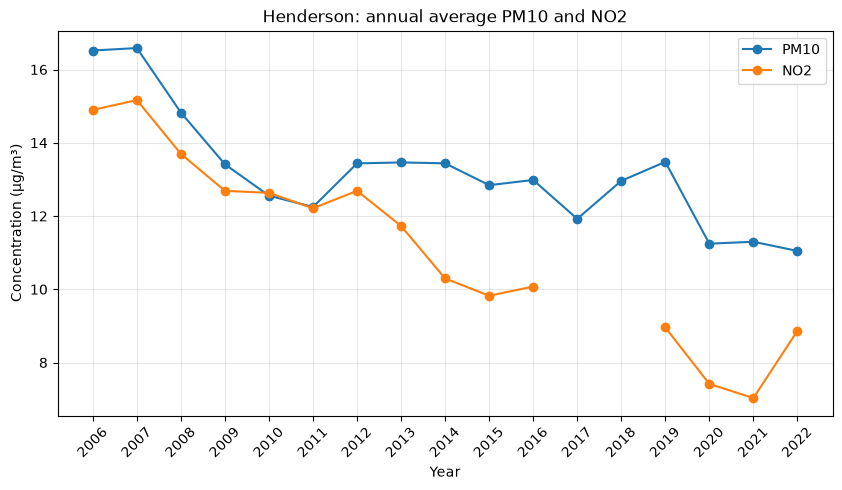

In [2]:
# yearly average and % of hours with data
yearly_mean = df[["PM10", "NO2"]].groupby(df.index.year).mean()
coverage = df[["PM10", "NO2"]].notna().groupby(df.index.year).mean()

# hide years with less than 75% data
yearly_mean = yearly_mean.where(coverage >= 0.75)
# 2023 only has Jan-Feb, so drop it
yearly_mean = yearly_mean.loc[:2022]

print(coverage.round(2))
yearly_mean.round(1)

# plot the trend
yearly_mean.plot(marker="o", figsize=(10, 5))
plt.title("Henderson: annual average PM10 and NO2")
plt.xlabel("Year")
plt.ylabel("Concentration (µg/m³)")
plt.grid(alpha=0.3)
plt.xticks(yearly_mean.index, rotation=45)
plt.show()

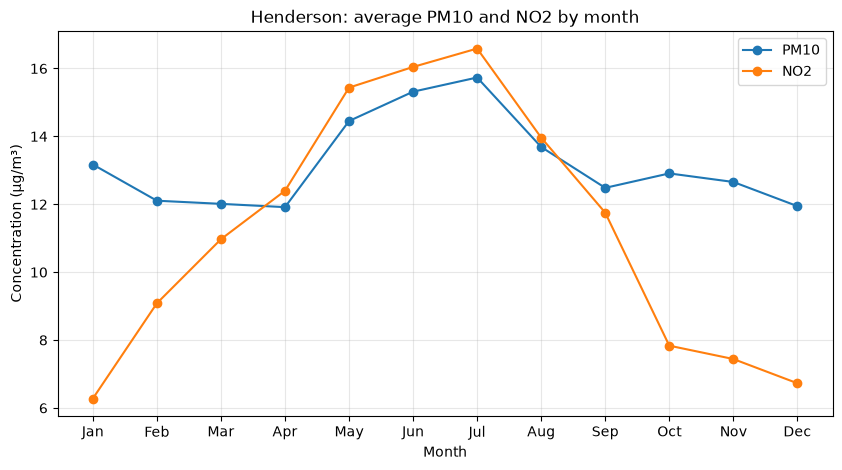

In [3]:
# average for each month across all years
monthly = df[["PM10", "NO2"]].groupby(df.index.month).mean()

# plot
monthly.plot(marker="o", figsize=(10, 5))
plt.title("Henderson: average PM10 and NO2 by month")
plt.xlabel("Month")
plt.ylabel("Concentration (µg/m³)")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.grid(alpha=0.3)
plt.show()

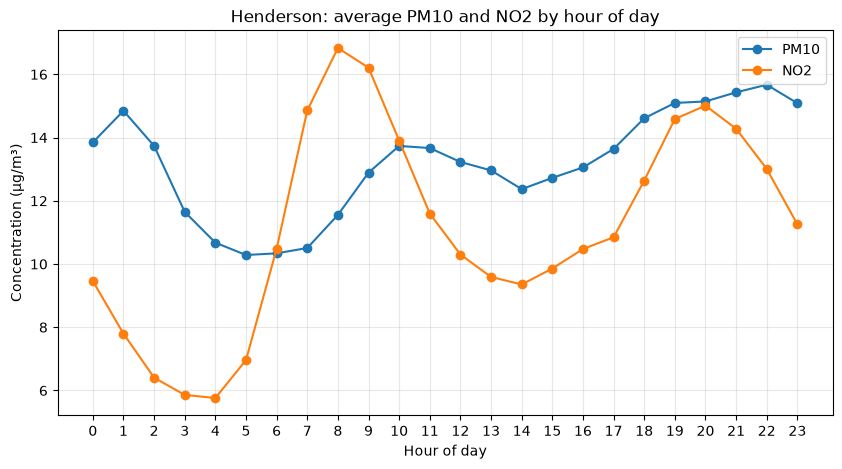

In [4]:
# average for each hour of the day across all years
hourly = df[["PM10", "NO2"]].groupby(df.index.hour).mean()

# plot
hourly.plot(marker="o", figsize=(10, 5))
plt.title("Henderson: average PM10 and NO2 by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Concentration (µg/m³)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

        PM10   NO2
Season            
Summer  12.4   7.3
Autumn  12.8  13.0
Winter  14.9  15.6
Spring  12.7   9.0


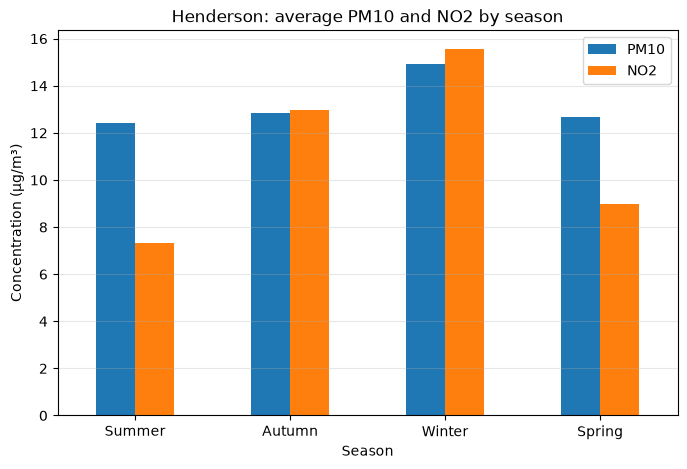

In [5]:
# map each month to an NZ season
season_map = {12: "Summer", 1: "Summer", 2: "Summer",
              3: "Autumn", 4: "Autumn", 5: "Autumn",
              6: "Winter", 7: "Winter", 8: "Winter",
              9: "Spring", 10: "Spring", 11: "Spring"}
df["Season"] = df.index.month.map(season_map)

# average per season, in calendar order
order = ["Summer", "Autumn", "Winter", "Spring"]
by_season = df.groupby("Season")[["PM10", "NO2"]].mean().loc[order]
print(by_season.round(1))

# bar chart
by_season.plot(kind="bar", figsize=(8, 5), rot=0)
plt.title("Henderson: average PM10 and NO2 by season")
plt.xlabel("Season")
plt.ylabel("Concentration (µg/m³)")
plt.grid(axis="y", alpha=0.3)
plt.show()

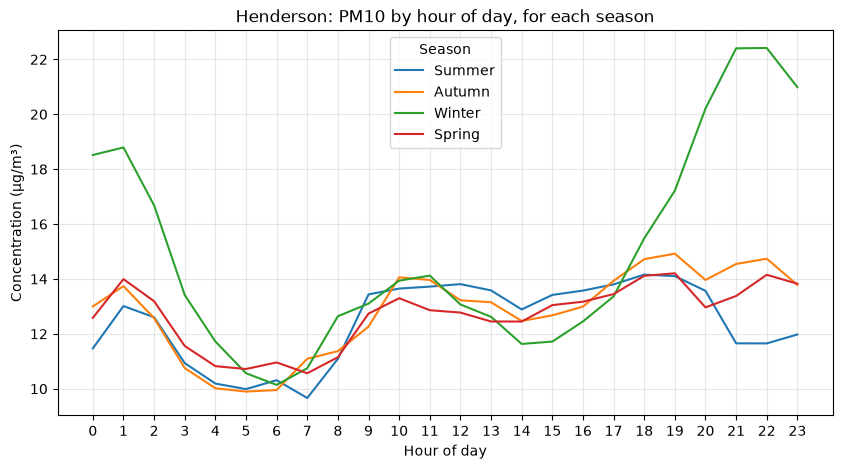

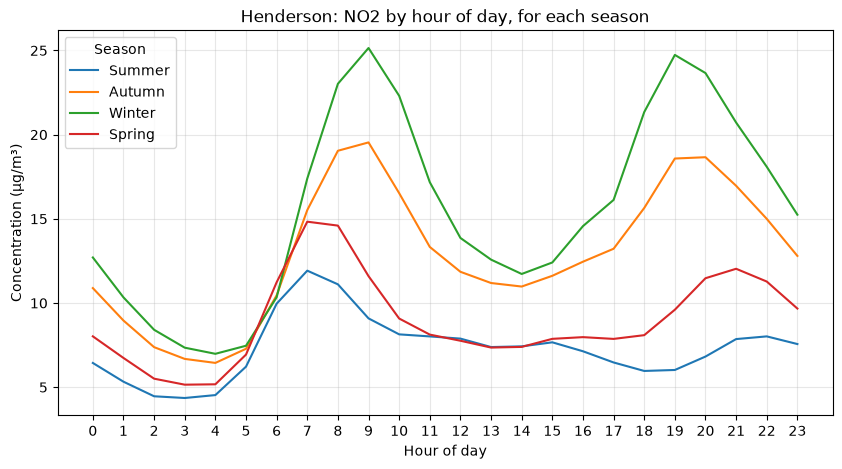

In [6]:
# daily pattern for each season
for col in ["PM10", "NO2"]:
    season_hour = df.groupby(["Season", df.index.hour])[col].mean().unstack(0)[order]
    season_hour.plot(figsize=(10, 5))
    plt.title(f"Henderson: {col} by hour of day, for each season")
    plt.xlabel("Hour of day")
    plt.ylabel("Concentration (µg/m³)")
    plt.xticks(range(0, 24))
    plt.grid(alpha=0.3)
    plt.show()

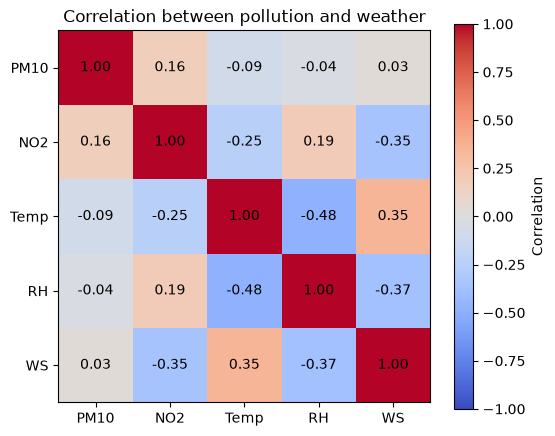

In [7]:
# correlation between all variables (-1 to 1)
# only the numeric columns (Season is text, so it is left out)
corr = df[["PM10", "NO2", "Temp", "RH", "WS"]].corr()
corr.round(2)


# heatmap of the correlations
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr)), corr.columns)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation between pollution and weather")
plt.show()

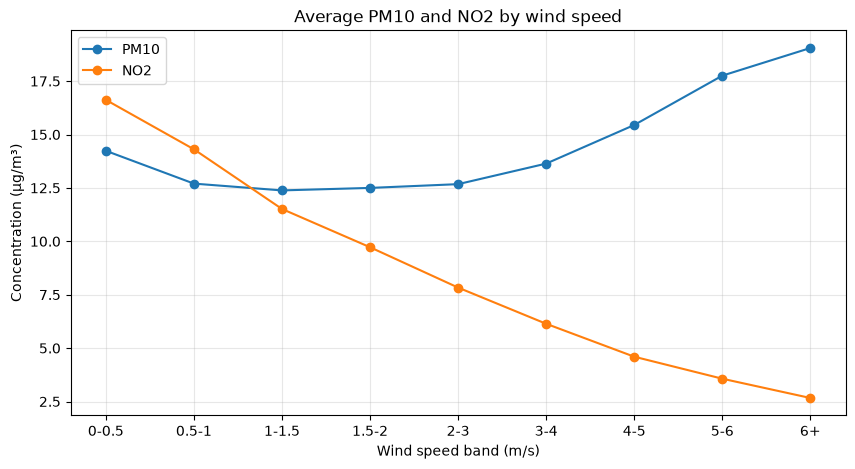

In [8]:
# group wind speed into bands
bins = [0, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 11]
df["WS_band"] = pd.cut(df["WS"], bins=bins, include_lowest=True)

# average pollution in each band
by_wind = df.groupby("WS_band", observed=True)[["PM10", "NO2"]].mean()

# plot
by_wind.plot(marker="o", figsize=(10, 5))
plt.title("Average PM10 and NO2 by wind speed")
plt.xlabel("Wind speed band (m/s)")
plt.ylabel("Concentration (µg/m³)")
plt.grid(alpha=0.3)
plt.xticks(range(len(by_wind)), ["0-0.5", "0.5-1", "1-1.5", "1.5-2", "2-3", "3-4", "4-5", "5-6", "6+"])
plt.show()


# remove the helper column
df = df.drop(columns="WS_band")

                                            feature engineering

In [91]:

# load the clean data and the measured-hours flags (both saved by the preprocessing notebook)
df = pd.read_csv("C:\\Users\\suraj\\Downloads\\henderson_clean_final_data.csv", index_col="datetime", parse_dates=True)

# True = really measured, False = a gap filled in during cleaning
measured = pd.read_csv("C:\\Users\\suraj\\Downloads\\henderson_measured_flags.csv", index_col="datetime", parse_dates=True).astype(bool)

print(df.shape, df.index.min(), "to", df.index.max())
print("share of hours really measured:")
print(measured.mean().round(3))

(150432, 5) 2006-01-01 00:00:00 to 2023-02-28 23:00:00
share of hours really measured:
NO2     0.878
PM10    0.956
RH      0.882
Temp    0.888
WS      0.895
dtype: float64


In [93]:
# Helper function
def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}


# example weeks (with dates) on the left, whole test set as a scatter on the right
def plot_actual_vs_pred(actual, pred, title, ylabel, start="2019-07-01", end="2019-07-14"):
    m = evaluate(actual, pred)
    fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [3, 1]})

    axes[0].plot(actual.loc[start:end], label="Actual", color="tab:blue", linewidth=1.5)
    axes[0].plot(pred.loc[start:end], label="Predicted", color="tab:orange", linewidth=1.5)
    axes[0].set_title(f"{start} to {end}")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel(ylabel)
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].scatter(actual, pred, s=4, alpha=0.3)
    lim = [0, max(actual.max(), pred.max())]
    axes[1].plot(lim, lim, color="red", linestyle="--", label="Perfect prediction")
    axes[1].set_title("Whole test set")
    axes[1].set_xlabel("Actual")
    axes[1].set_ylabel("Predicted")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(f"{title}   |   MAE = {m['MAE']:.2f}   RMSE = {m['RMSE']:.2f}   R² = {m['R2']:.3f}",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


# train one model, predict the test set, store the predictions, plot
def run_model(name, model, train, test, features, preds, title, ylabel):
    model.fit(train[features], train["target"])
    pred = pd.Series(model.predict(test[features]), index=test.index)
    preds[name] = pred
    m = evaluate(test["target"], pred)
    print(f"{name}:  MAE = {m['MAE']:.3f}   RMSE = {m['RMSE']:.3f}   R² = {m['R2']:.3f}")
    plot_actual_vs_pred(test["target"], pred, f"{title} - {name}", ylabel)
    return model


# Prophet needs columns ds (time) and y (value); weather is added as extra inputs
def run_prophet(train, test, preds, title, ylabel):
    def to_prophet(d):
        return pd.DataFrame({"ds": d.index + pd.Timedelta(hours=1),   # target is the next hour
                             "y": d["target"].values,
                             "Temp": d["Temp"].values,
                             "RH": d["RH"].values,
                             "WS": d["WS"].values})

    p_train, p_test = to_prophet(train), to_prophet(test)
    m = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=True)
    for reg in ["Temp", "RH", "WS"]:
        m.add_regressor(reg)
    m.fit(p_train)

    pred = pd.Series(m.predict(p_test.drop(columns="y"))["yhat"].clip(lower=0).values, index=test.index)
    preds["Prophet"] = pred
    s = evaluate(test["target"], pred)
    print(f"Prophet:  MAE = {s['MAE']:.3f}   RMSE = {s['RMSE']:.3f}   R² = {s['R2']:.3f}")
    plot_actual_vs_pred(test["target"], pred, f"{title} - Prophet", ylabel)


# one table for all models: MAE, RMSE, R2 and skill vs the naive guess
# mask = which test rows to score (e.g. only hours that were really measured)
def results_table(preds, test, naive, mask=None):
    if mask is None:
        mask = np.ones(len(test), dtype=bool)
    y = test["target"].values[mask]
    naive_rmse = np.sqrt(mean_squared_error(y, naive.values[mask]))
    rows = []
    for name, pred in {"Naive (simple guess)": naive, **preds}.items():
        m = evaluate(y, pred.values[mask])
        rows.append({"Model": name, **m, "Skill vs naive": 1 - m["RMSE"] / naive_rmse})
    return pd.DataFrame(rows).round(3).sort_values("RMSE").reset_index(drop=True)


# the same model settings are used for both pollutants
model_lookup = {
    "Linear Regression": lambda: LinearRegression(),
    "Decision Tree": lambda: DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42),
    "XGBoost (tuned)": lambda: XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                            min_child_weight=20, random_state=42),
    "LightGBM": lambda: LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
}

In [95]:
# Next hour features
def make_features(df, target):
    X = pd.DataFrame(index=df.index)

    # time features
    X["hour"] = df.index.hour
    X["month"] = df.index.month
    X["dayofweek"] = df.index.dayofweek
    X["is_weekend"] = (X["dayofweek"] >= 5).astype(int)

    # current weather
    for col in ["Temp", "RH", "WS"]:
        X[col] = df[col]

    # past pollution values (lag0 = now, lag1 = 1 hour ago, lag24 = same time yesterday)
    for lag in [0, 1, 2, 3, 24]:
        X[f"{target}_lag{lag}"] = df[target].shift(lag)

    # recent averages
    X[f"{target}_roll3"] = df[target].rolling(3).mean()
    X[f"{target}_roll24"] = df[target].rolling(24).mean()

    # target = value next hour
    y = df[target].shift(-1).rename("target")

    # drop rows with any missing value
    return pd.concat([X, y], axis=1).dropna()


# chronological 80/20 split (no shuffling)
def split_80_20(d):
    cut = int(len(d) * 0.8)
    return d.iloc[:cut], d.iloc[cut:]


# True for test rows whose target hour was really measured
def measured_mask(test, t, hours_ahead=1):
    return measured[t].reindex(test.index + pd.Timedelta(hours=hours_ahead), fill_value=False).values

In [13]:
%pip install xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

                NO₂ – next-hour forecast

In [98]:
# Features and 80/20 split
no2 = make_features(df, "NO2")
no2_train, no2_test = split_80_20(no2)
no2_features = [c for c in no2.columns if c != "target"]

print("NO2 train:", len(no2_train), no2_train.index.min(), "to", no2_train.index.max())
print("NO2 test: ", len(no2_test), no2_test.index.min(), "to", no2_test.index.max())

no2_preds = {}   # predictions of every model on the test set
no2_label = "NO2 (µg/m³)"

NO2 train: 97396 2006-01-02 00:00:00 to 2017-07-15 06:00:00
NO2 test:  24350 2017-07-15 07:00:00 to 2023-01-31 23:00:00


In [100]:
# naive baseline: next hour = this hour (reference point, not one of the six models)
no2_naive = no2_test["NO2_lag0"]
print("NO2 naive baseline:", {k: round(v, 3) for k, v in evaluate(no2_test["target"], no2_naive).items()})

NO2 naive baseline: {'MAE': 2.858, 'RMSE': np.float64(4.892), 'R2': 0.655}


Linear Regression:  MAE = 2.926   RMSE = 4.519   R² = 0.706


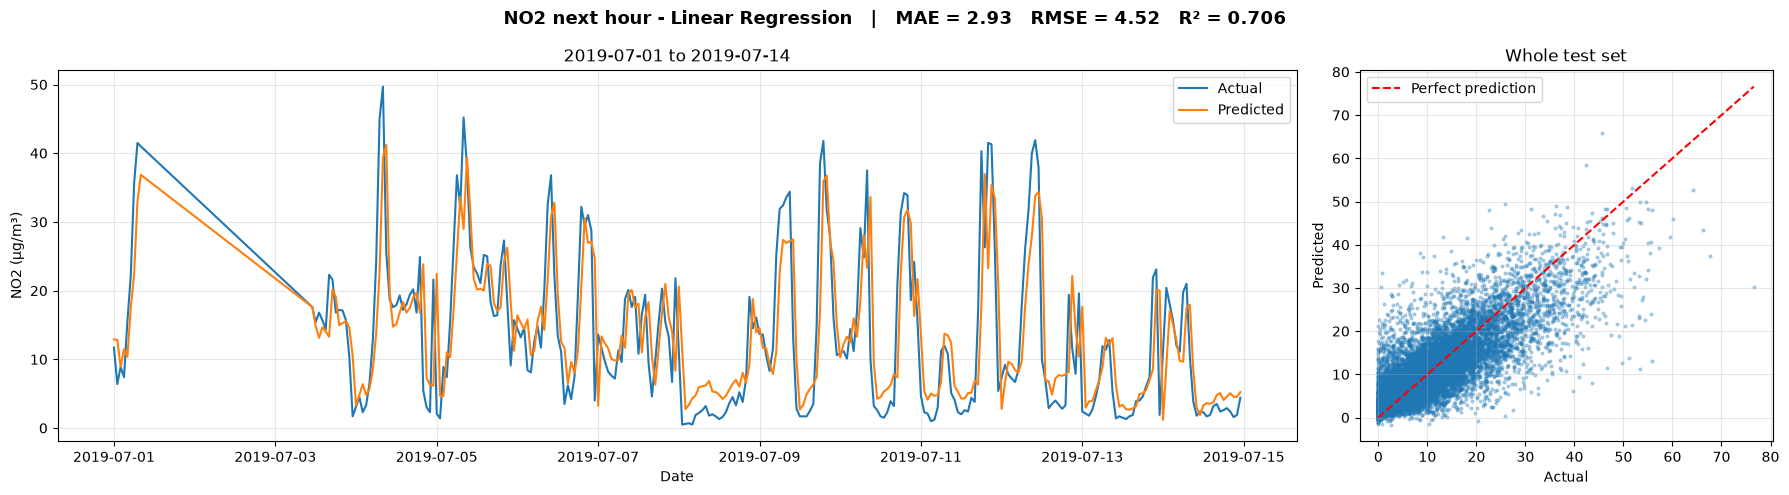

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[ 0.05,-0.04,-0.07,..., 0.04, 0.18, 0.2 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['hour','month','dayofweek',...,'NO2_lag24','NO2_roll3','NO2_roll24']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.807
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [102]:
# Model 1: Linear Regression
run_model("Linear Regression", model_lookup["Linear Regression"](), no2_train, no2_test,
          no2_features, no2_preds, "NO2 next hour", no2_label)

Decision Tree:  MAE = 2.791   RMSE = 4.511   R² = 0.707


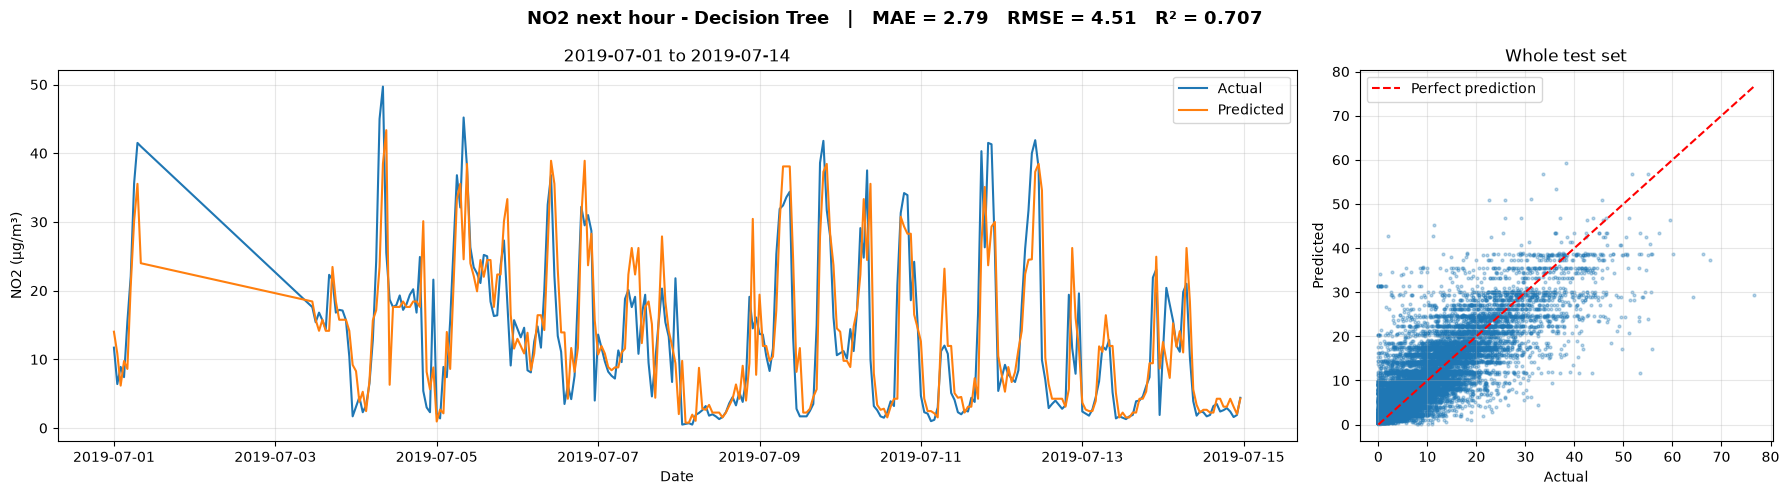

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

In [104]:
# Model 2: Decision Tree
run_model("Decision Tree", model_lookup["Decision Tree"](), no2_train, no2_test,
          no2_features, no2_preds, "NO2 next hour", no2_label)

Random Forest:  MAE = 2.602   RMSE = 4.111   R² = 0.757


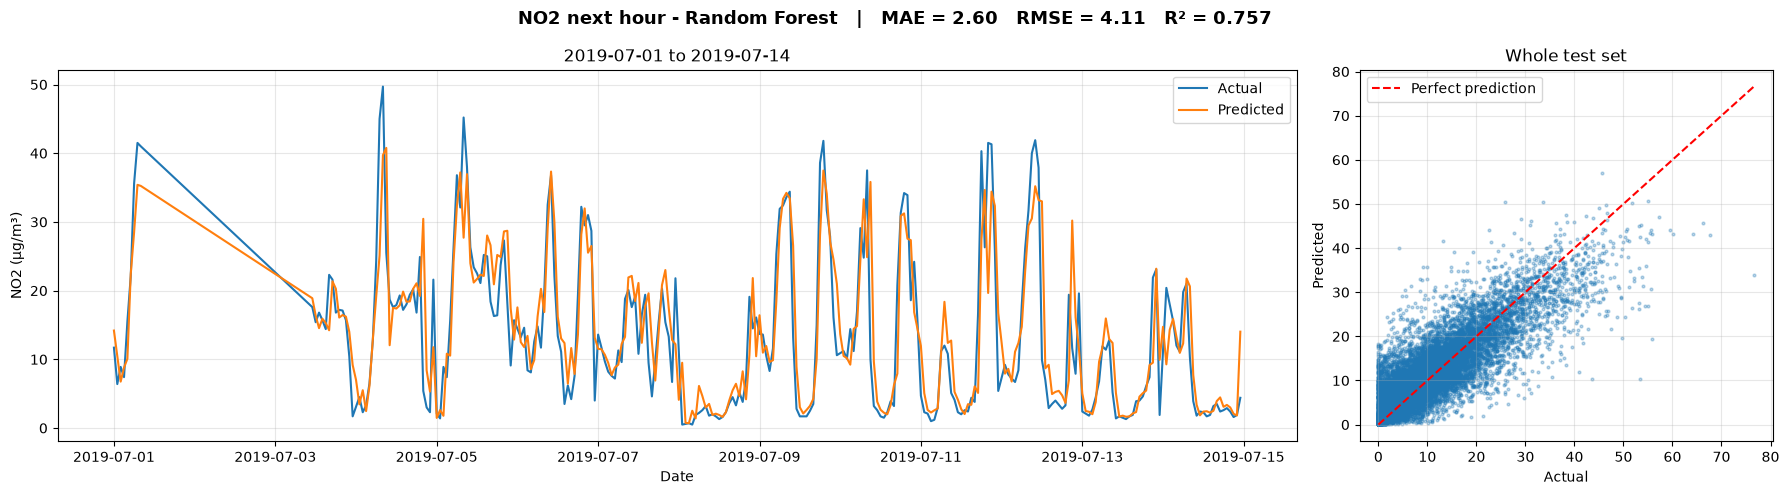

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [106]:
# Model 3: Random Forest
run_model("Random Forest", model_lookup["Random Forest"](), no2_train, no2_test,
          no2_features, no2_preds, "NO2 next hour", no2_label)

XGBoost (tuned):  MAE = 2.559   RMSE = 3.999   R² = 0.770


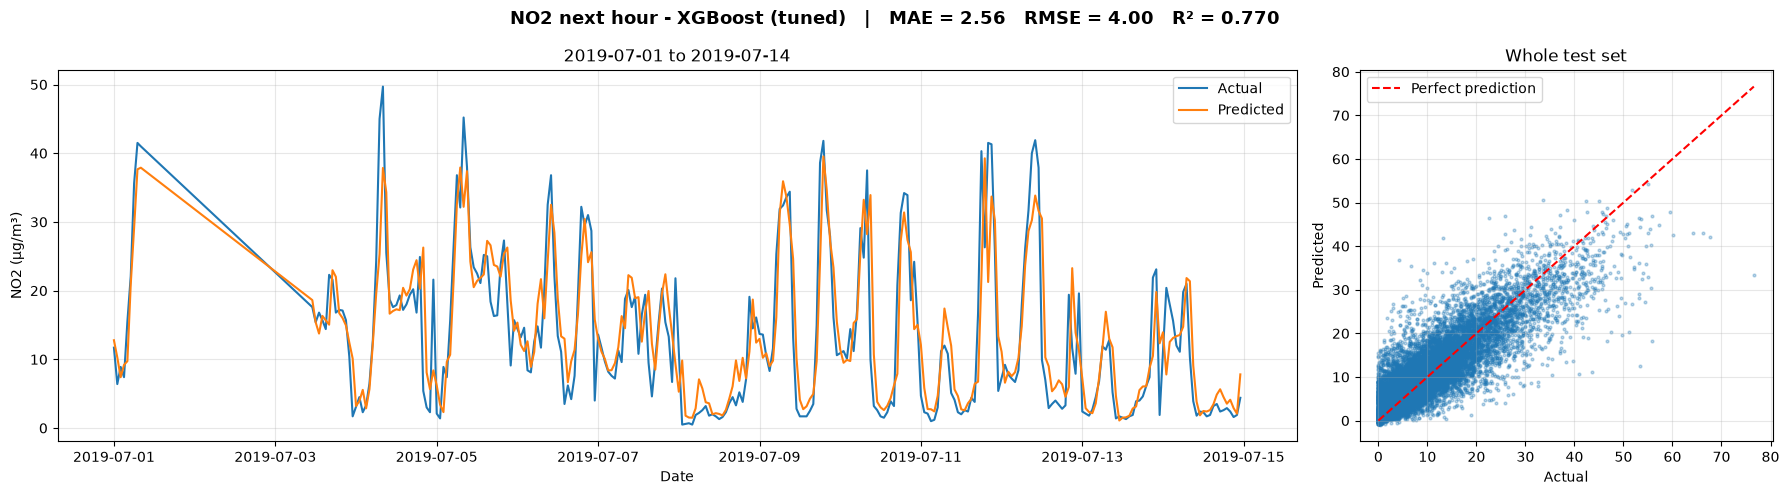

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [108]:
# Model 4b: XGBoost with stricter settings
run_model("XGBoost (tuned)", model_lookup["XGBoost (tuned)"](), no2_train, no2_test,
          no2_features, no2_preds, "NO2 next hour", no2_label)

LightGBM:  MAE = 2.487   RMSE = 3.891   R² = 0.782


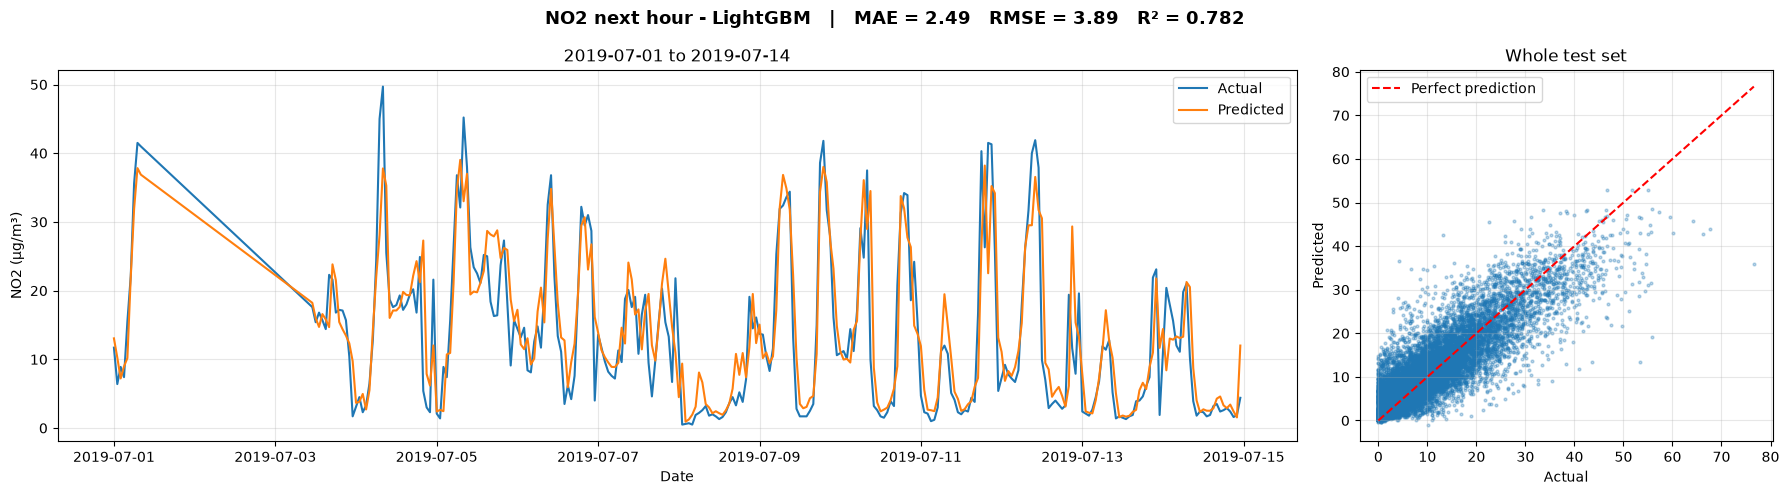

,learning_rate,0.05
,n_estimators,300
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [110]:
# Model 5: LightGBM
run_model("LightGBM", model_lookup["LightGBM"](), no2_train, no2_test,
          no2_features, no2_preds, "NO2 next hour", no2_label)



In [23]:
%pip install prophet

Note: you may need to restart the kernel to use updated packages.


18:17:10 - cmdstanpy - INFO - Chain [1] start processing
18:18:07 - cmdstanpy - INFO - Chain [1] done processing


Prophet:  MAE = 5.464   RMSE = 7.091   R² = 0.276


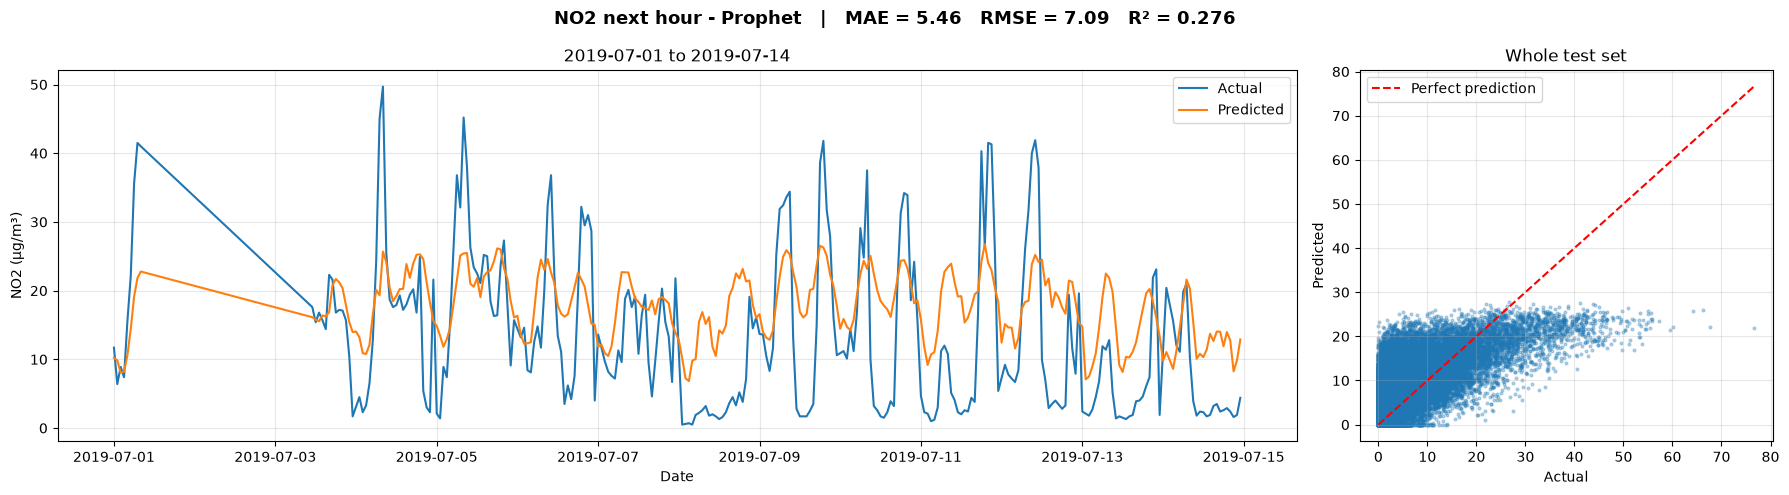

In [113]:
# Model 6: Prophet
run_prophet(no2_train, no2_test, no2_preds, "NO2 next hour", no2_label)

In [115]:
# NO₂ results
no2_mask = measured_mask(no2_test, "NO2")
print(f"{no2_mask.mean() * 100:.1f}% of NO2 test targets were really measured")

print("NO2 - all test hours")
display(results_table(no2_preds, no2_test, no2_naive))

no2_results = results_table(no2_preds, no2_test, no2_naive, no2_mask)
print("NO2 - measured hours only (final table)")
display(no2_results)

97.5% of NO2 test targets were really measured
NO2 - all test hours


,Model,MAE,RMSE,R2,Skill vs naive
0,LightGBM,2.487,3.891,0.782,0.205
1,XGBoost (tuned),2.559,3.999,0.770,0.183
2,Random Forest,2.602,4.111,0.757,0.160
3,Decision Tree,2.791,4.511,0.707,0.078
4,Linear Regression,2.926,4.519,0.706,0.076
5,Naive (simple guess),2.858,4.892,0.655,0.000
6,Prophet,5.464,7.091,0.276,-0.449


NO2 - measured hours only (final table)


,Model,MAE,RMSE,R2,Skill vs naive
0,LightGBM,2.501,3.909,0.783,0.207
1,XGBoost (tuned),2.576,4.025,0.770,0.183
2,Random Forest,2.608,4.125,0.758,0.163
3,Decision Tree,2.797,4.524,0.709,0.082
4,Linear Regression,2.945,4.552,0.705,0.076
5,Naive (simple guess),2.874,4.928,0.655,0.000
6,Prophet,5.520,7.149,0.273,-0.451


In [125]:
# scores of the best NO2 model on the whole test set
no2_scores = evaluate(actual, pred)
no2_mae = no2_scores["MAE"]
no2_rmse = no2_scores["RMSE"]
no2_r2 = no2_scores["R2"]

Best NO2 model: LightGBM


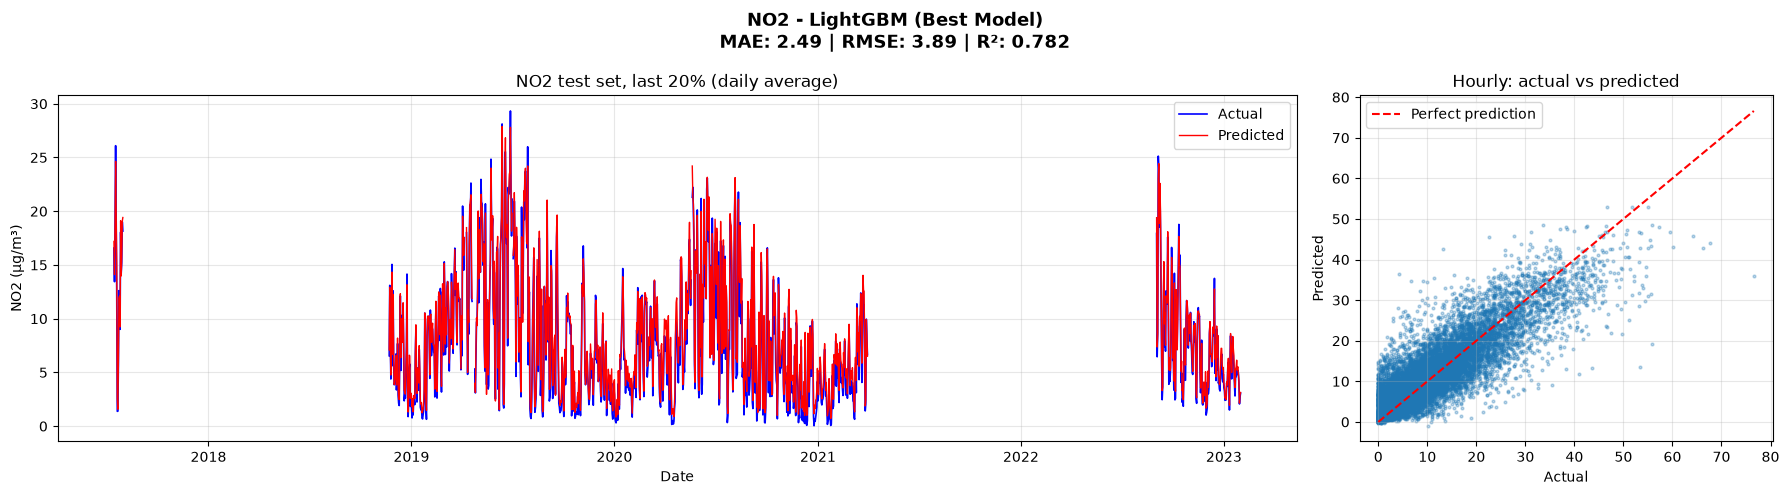

In [131]:
# Best NO₂ model
no2_best = no2_results[no2_results["Model"] != "Naive (simple guess)"].iloc[0]["Model"]
print("Best NO2 model:", no2_best)

# whole test set as daily averages + hourly scatter
actual, pred = no2_test["target"], no2_preds[no2_best]
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [3, 1]})
axes[0].plot(actual.resample("D").mean(), label="Actual", color="blue", linewidth=1.2)
axes[0].plot(pred.resample("D").mean(), label="Predicted", color="red", linewidth=1)
axes[0].set_title("NO2 test set, last 20% (daily average)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel(no2_label)
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].scatter(actual, pred, s=4, alpha=0.3)
lim = [0, max(actual.max(), pred.max())]
axes[1].plot(lim, lim, color="red", linestyle="--", label="Perfect prediction")
axes[1].set_title("Hourly: actual vs predicted")
axes[1].set_xlabel("Actual")
axes[1].set_ylabel("Predicted")
axes[1].legend()
axes[1].grid(alpha=0.3)
fig.suptitle(
    f"NO2 - {no2_best} (Best Model)\n"
    f"MAE: {no2_mae:.2f} | RMSE: {no2_rmse:.2f} | R²: {no2_r2:.3f}",
    fontsize=13,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

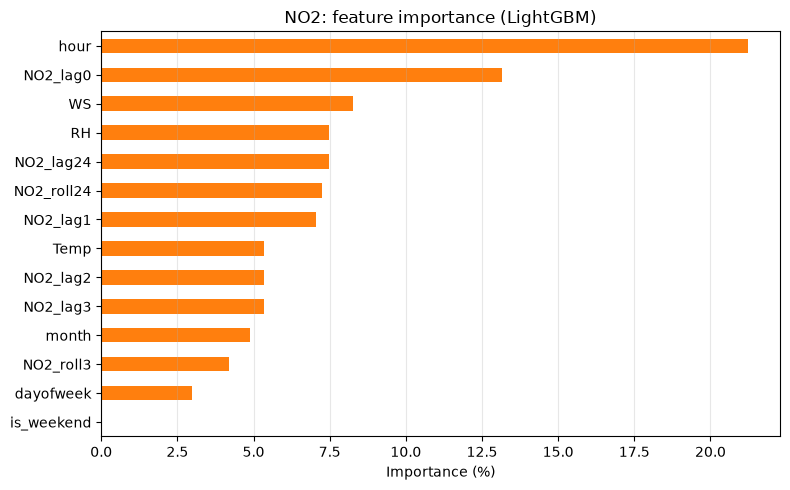

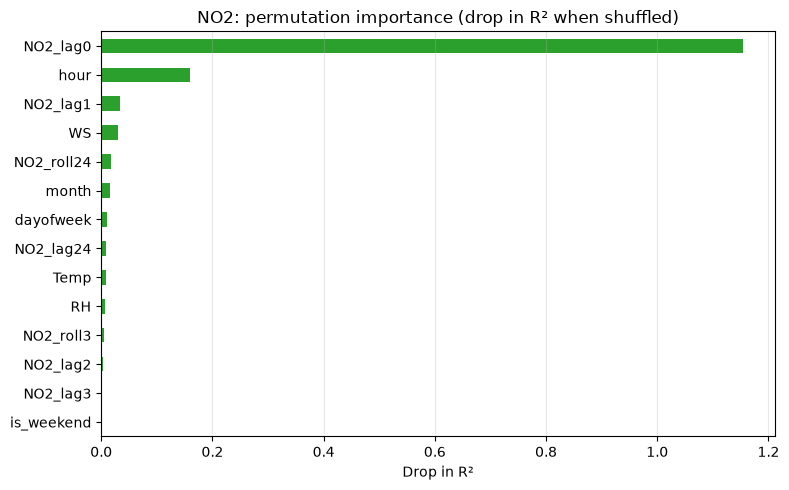

In [133]:
# retrain the best model so its importance can be read
no2_model = model_lookup[no2_best]()
no2_model.fit(no2_train[no2_features], no2_train["target"])

if hasattr(no2_model, "feature_importances_"):
    imp = pd.Series(no2_model.feature_importances_, index=no2_features)
    imp = (imp / imp.sum() * 100).sort_values()
    imp.plot(kind="barh", figsize=(8, 5), color="tab:orange")
    plt.title(f"NO2: feature importance ({no2_best})")
    plt.xlabel("Importance (%)")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

perm = permutation_importance(no2_model, no2_test[no2_features], no2_test["target"],
                              n_repeats=5, random_state=42, n_jobs=-1, scoring="r2")
pd.Series(perm.importances_mean, index=no2_features).sort_values().plot(kind="barh", figsize=(8, 5), color="tab:green")
plt.title("NO2: permutation importance (drop in R² when shuffled)")
plt.xlabel("Drop in R²")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

,Removed,R2 without,Drop in R2
0,Weather,0.776,0.006
1,Recent NO2,0.251,0.531
2,Time,0.729,0.053


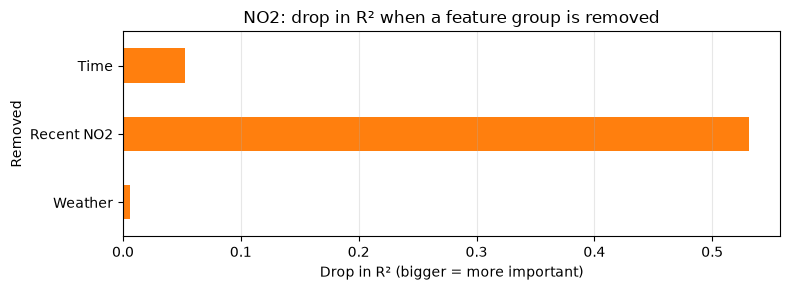

In [134]:
# group importance: remove a group of features, retrain, compare R2
no2_groups = {
    "Weather": ["Temp", "RH", "WS"],
    "Recent NO2": ["NO2_lag0", "NO2_lag1", "NO2_lag2", "NO2_lag3", "NO2_lag24", "NO2_roll3", "NO2_roll24"],
    "Time": ["hour", "month", "dayofweek", "is_weekend"],
}
base_r2 = r2_score(no2_test["target"], no2_model.predict(no2_test[no2_features]))
rows = []
for group, cols in no2_groups.items():
    keep = [c for c in no2_features if c not in cols]
    m = model_lookup[no2_best]().fit(no2_train[keep], no2_train["target"])
    r2 = r2_score(no2_test["target"], m.predict(no2_test[keep]))
    rows.append({"Removed": group, "R2 without": round(r2, 3), "Drop in R2": round(base_r2 - r2, 3)})
no2_groups_df = pd.DataFrame(rows)
display(no2_groups_df)

no2_groups_df.set_index("Removed")["Drop in R2"].plot(kind="barh", figsize=(8, 3), color="tab:orange")
plt.title("NO2: drop in R² when a feature group is removed")
plt.xlabel("Drop in R² (bigger = more important)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

                    PM10

In [137]:
#Hourly PM10 (starting point)
pm10 = make_features(df, "PM10")
pm10_train, pm10_test = split_80_20(pm10)
pm10_features = [c for c in pm10.columns if c != "target"]

print("PM10 train:", len(pm10_train), pm10_train.index.min(), "to", pm10_train.index.max())
print("PM10 test: ", len(pm10_test), pm10_test.index.min(), "to", pm10_test.index.max())

pm10_preds = {}
pm10_label = "PM10 (µg/m³)"
pm10_naive = pm10_test["PM10_lag0"]          # simple guess: next hour = this hour

PM10 train: 103984 2006-01-02 00:00:00 to 2018-07-21 03:00:00
PM10 test:  25997 2018-07-21 04:00:00 to 2023-01-31 23:00:00


Linear Regression:  MAE = 4.402   RMSE = 6.004   R² = 0.321


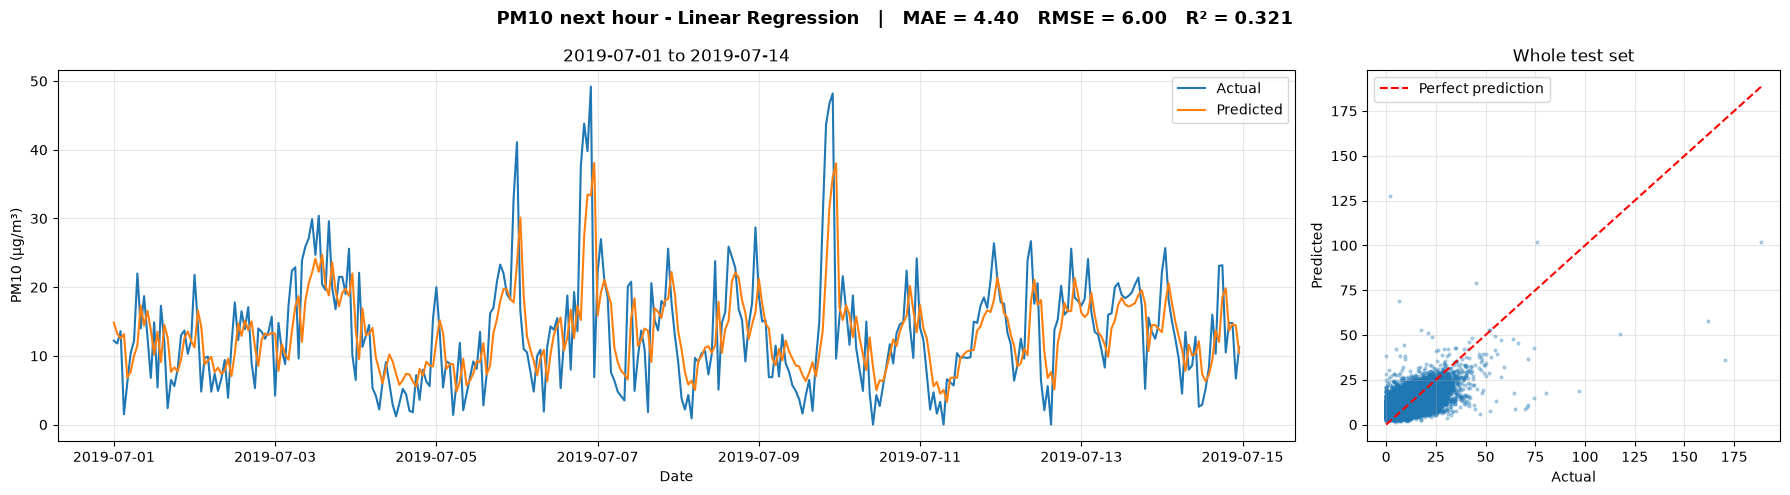

Decision Tree:  MAE = 4.339   RMSE = 6.130   R² = 0.292


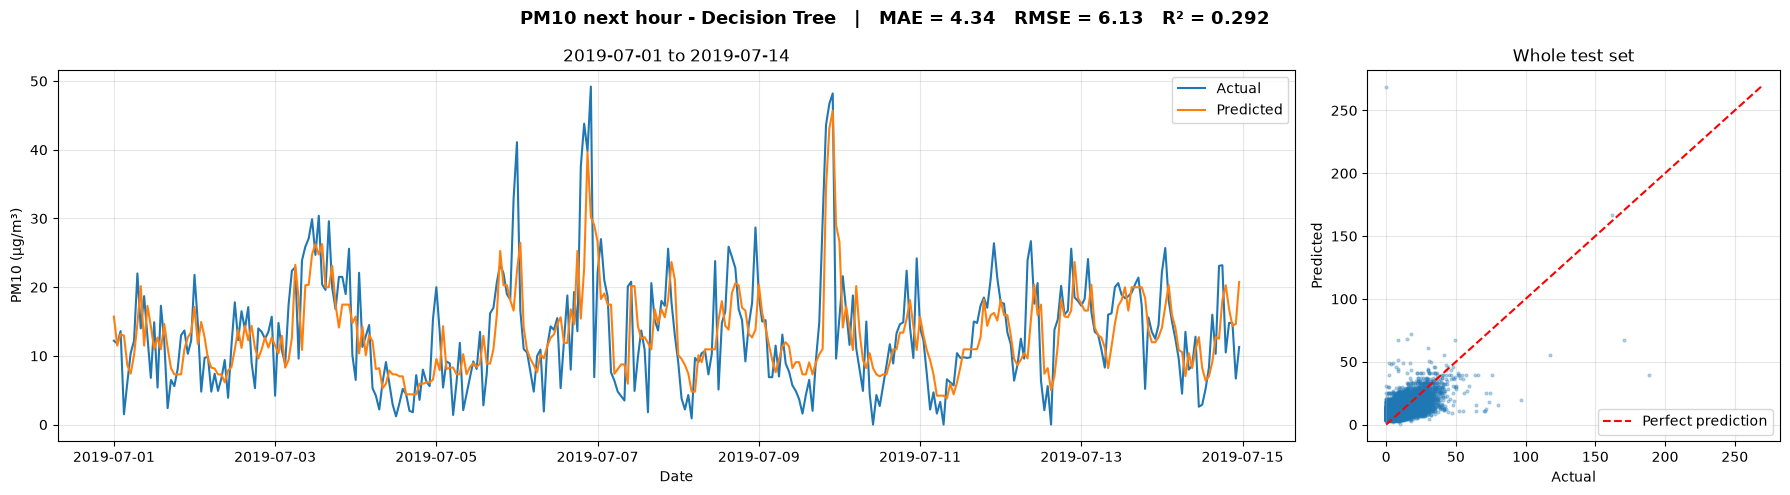

Random Forest:  MAE = 4.202   RMSE = 5.789   R² = 0.369


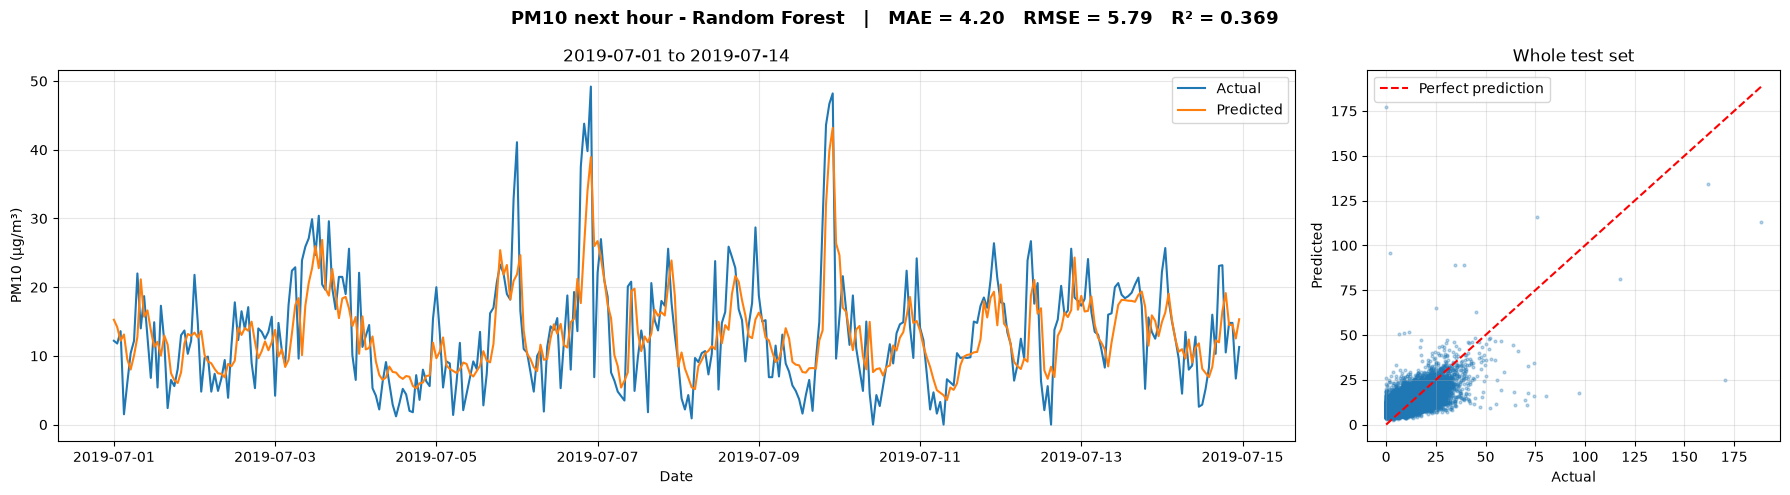

XGBoost (tuned):  MAE = 4.168   RMSE = 5.781   R² = 0.370


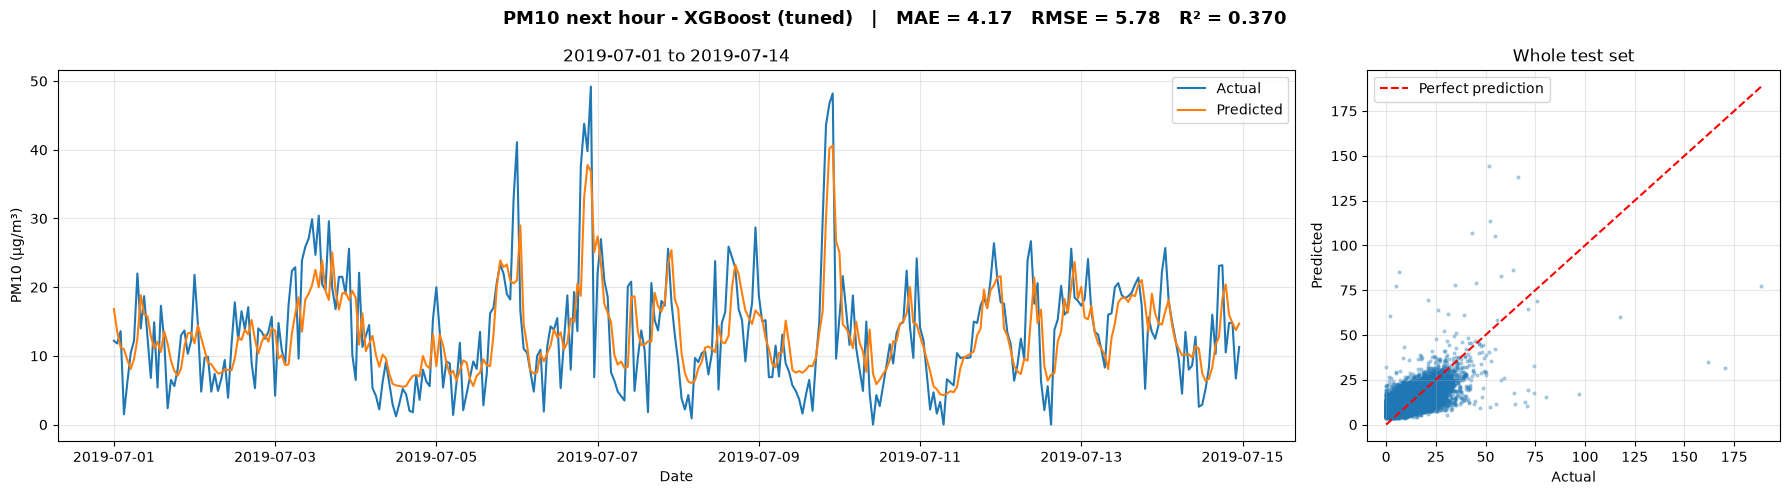

LightGBM:  MAE = 4.134   RMSE = 5.738   R² = 0.380


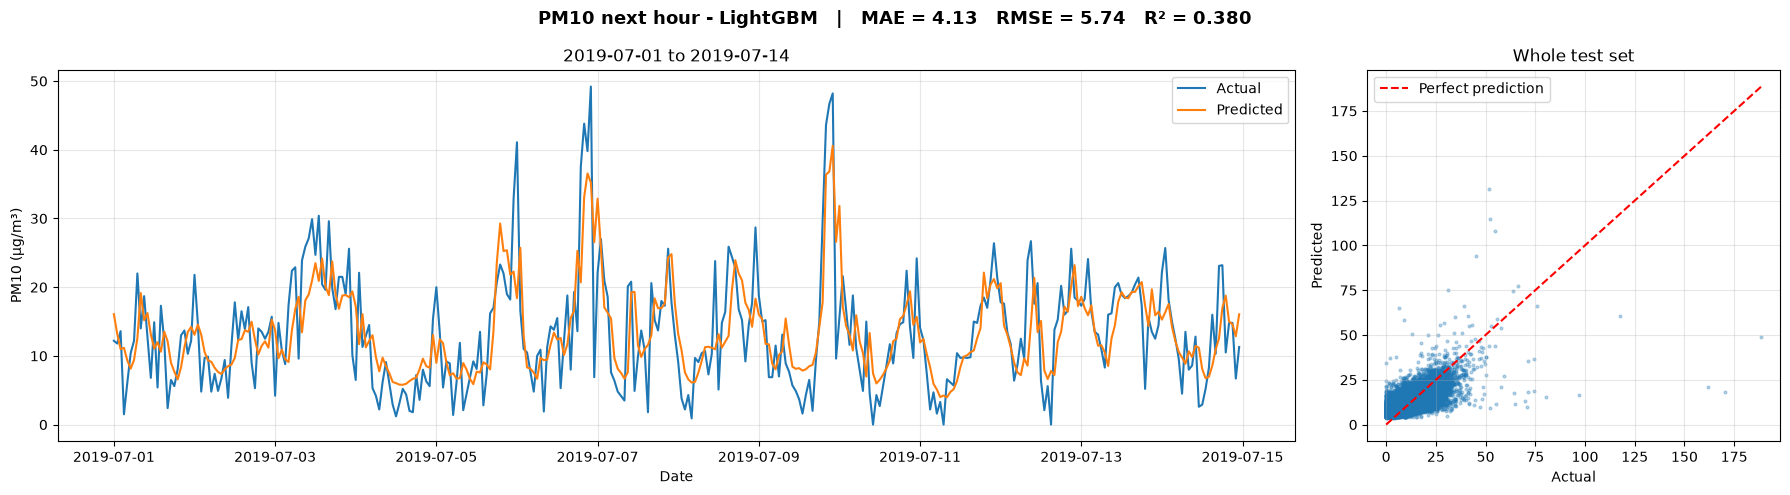

In [140]:
# Hourly models
for name in model_lookup:
    run_model(name, model_lookup[name](), pm10_train, pm10_test,
              pm10_features, pm10_preds, "PM10 next hour", pm10_label)
    

18:46:04 - cmdstanpy - INFO - Chain [1] start processing
18:46:49 - cmdstanpy - INFO - Chain [1] done processing


Prophet:  MAE = 5.331   RMSE = 7.201   R² = 0.023


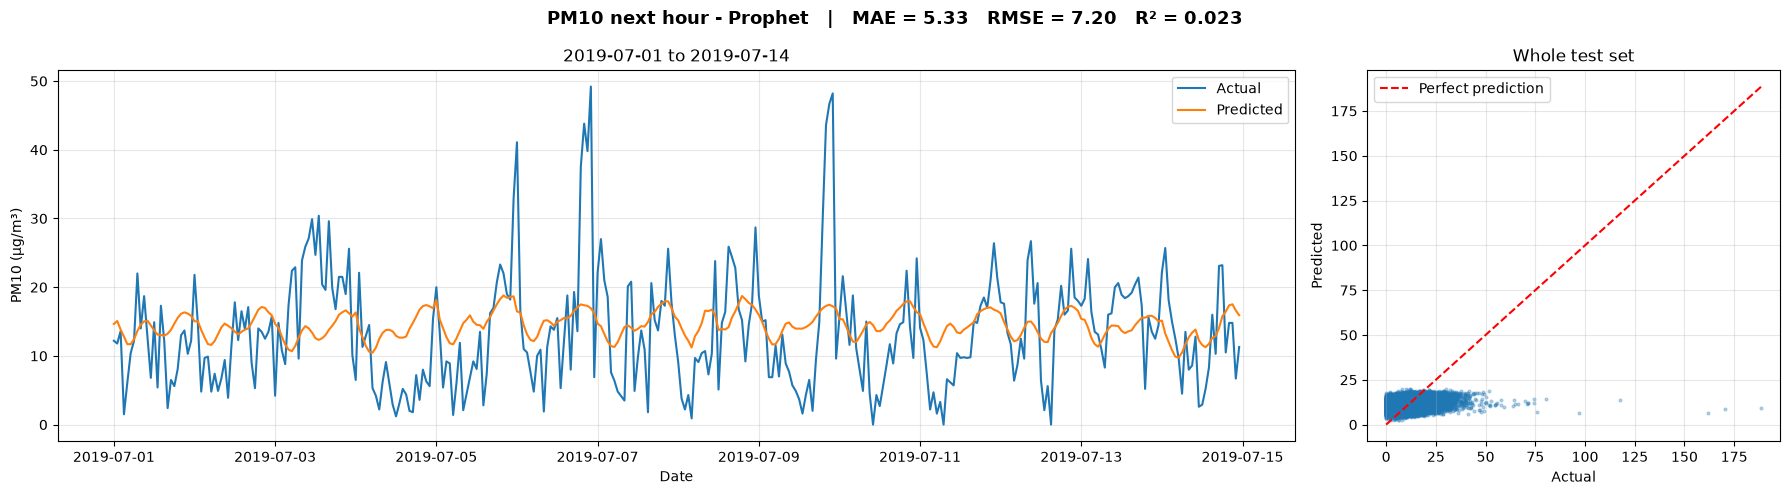

In [142]:
run_prophet(pm10_train, pm10_test, pm10_preds, "PM10 next hour", pm10_label)

In [144]:
# Hourly PM10 results
pm10_mask = measured_mask(pm10_test, "PM10")
print(f"{pm10_mask.mean() * 100:.1f}% of PM10 test targets were really measured")

print("PM10 next hour - all test hours")
display(results_table(pm10_preds, pm10_test, pm10_naive))

pm10_hourly_results = results_table(pm10_preds, pm10_test, pm10_naive, pm10_mask)
print("PM10 next hour - measured hours only")
display(pm10_hourly_results)

pm10_hourly_best = pm10_hourly_results[pm10_hourly_results["Model"] != "Naive (simple guess)"].iloc[0]["Model"]
print("Best hourly PM10 model:", pm10_hourly_best)

97.7% of PM10 test targets were really measured
PM10 next hour - all test hours


,Model,MAE,RMSE,R2,Skill vs naive
0,LightGBM,4.134,5.738,0.380,0.189
1,XGBoost (tuned),4.168,5.781,0.370,0.183
2,Random Forest,4.202,5.789,0.369,0.182
3,Linear Regression,4.402,6.004,0.321,0.151
4,Decision Tree,4.339,6.130,0.292,0.134
5,Naive (simple guess),5.195,7.076,0.057,0.000
6,Prophet,5.331,7.201,0.023,-0.018


PM10 next hour - measured hours only


,Model,MAE,RMSE,R2,Skill vs naive
0,LightGBM,4.175,5.786,0.376,0.189
1,XGBoost (tuned),4.211,5.831,0.366,0.183
2,Random Forest,4.244,5.837,0.365,0.182
3,Linear Regression,4.456,6.061,0.315,0.150
4,Decision Tree,4.382,6.181,0.288,0.134
5,Naive (simple guess),5.254,7.134,0.051,0.000
6,Prophet,5.358,7.240,0.023,-0.015


Best hourly PM10 model: LightGBM


In [146]:
# next 3-hour average PM10
def make_pm10_avg(df, hours):
    X = pd.DataFrame(index=df.index)
    X["hour"] = df.index.hour
    X["month"] = df.index.month
    X["dayofweek"] = df.index.dayofweek
    X["is_weekend"] = (X["dayofweek"] >= 5).astype(int)
    X["fireworks_days"] = ((df.index.month == 11) & (df.index.day.isin([4, 5, 6]))).astype(int)
    X["era_2017"] = (df.index.year >= 2017).astype(int)

    for col in ["Temp", "RH", "WS"]:
        X[col] = df[col]                                  # gaps stay as NaN

    s = df["PM10"]
    for lag in [0, 1, 2, 3, 24]:
        X[f"PM10_lag{lag}"] = s.shift(lag)
    X["PM10_roll3"] = s.rolling(3, min_periods=2).mean()
    X["PM10_roll24"] = s.rolling(24, min_periods=18).mean()
    X["PM10_std24"] = s.rolling(24, min_periods=18).std()
    X["NO2_lag0"] = df["NO2"]
    X["NO2_roll24"] = df["NO2"].rolling(24, min_periods=18).mean()

    # target = average of hours t+1 ... t+hours, and how much of it was really measured
    target = s.rolling(hours).mean().shift(-hours)
    measured_frac = measured["PM10"].astype(float).rolling(hours).mean().shift(-hours)

    d = pd.concat([X, target.rename("target"), measured_frac.rename("measured_frac")], axis=1)
    keep = d["target"].notna() & d["PM10_lag0"].notna() & (d["measured_frac"] >= 0.75)
    return d[keep]


def split_avg(d, hours):
    # chronological 80/20; training targets must END before the test period starts
    test_start = d.index[int(len(d) * 0.8)]
    train = d[d.index + pd.Timedelta(hours=hours) < test_start]
    test = d[d.index >= test_start]
    return train, test


pm10_3h = make_pm10_avg(df, 3)
pm10_3h_train, pm10_3h_test = split_avg(pm10_3h, 3)
pm10_3h_features = [c for c in pm10_3h.columns if c not in ["target", "measured_frac", "era_2017"]]

print("3h train:", len(pm10_3h_train), pm10_3h_train.index.min(), "to", pm10_3h_train.index.max())
print("3h test: ", len(pm10_3h_test), pm10_3h_test.index.min(), "to", pm10_3h_test.index.max())

pm10_3h_preds = {}
pm10_3h_label = "PM10, 3-hour average (µg/m³)"
# simple guess: next 3-hour average = last 3-hour average
pm10_3h_naive = pm10_3h_test["PM10_roll3"].fillna(pm10_3h_test["PM10_lag0"])
print("3h naive:", {k: round(v, 3) for k, v in evaluate(pm10_3h_test["target"], pm10_3h_naive).items()})

3h train: 111973 2006-01-01 00:00:00 to 2019-06-04 14:00:00
3h test:  27994 2019-06-04 18:00:00 to 2023-02-28 20:00:00
3h naive: {'MAE': 3.851, 'RMSE': np.float64(5.62), 'R2': 0.129}


In [150]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

Linear Regression:  MAE = 3.422   RMSE = 4.831   R² = 0.356


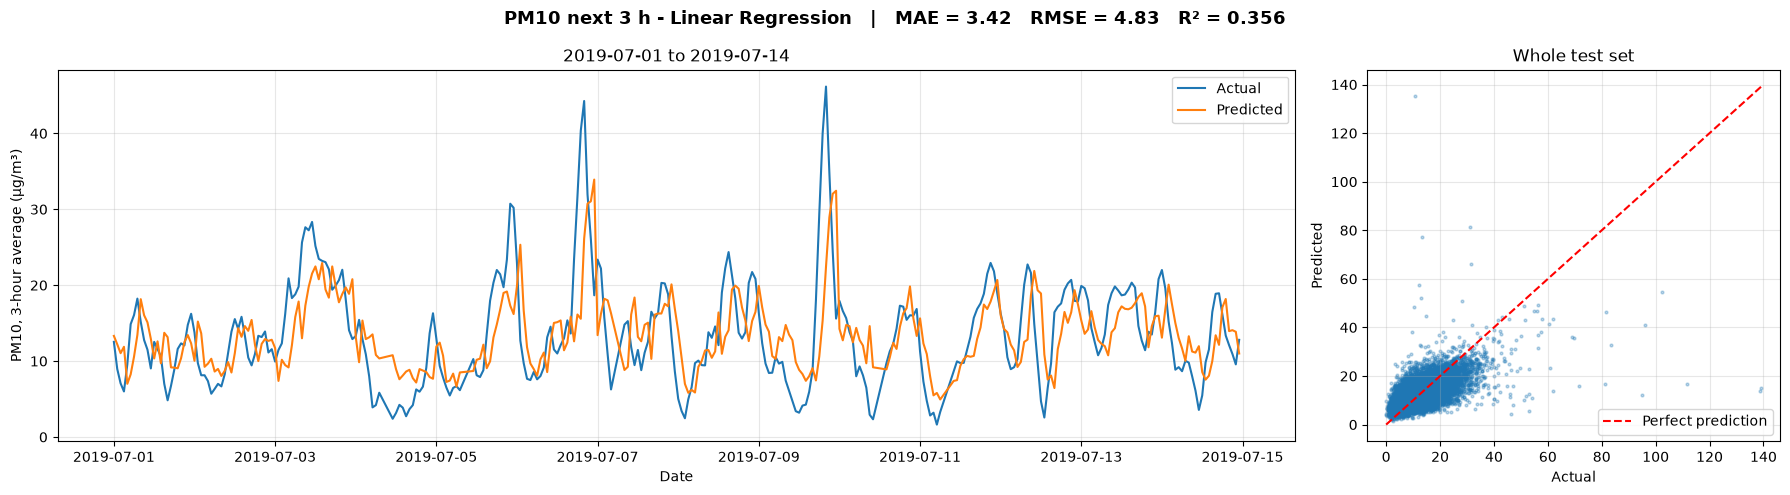

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['hour','month','dayofweek',...,'PM10_std24','NO2_lag0','NO2_roll24']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object dat

In [152]:
# Model 1: Linear Regression

run_model("Linear Regression", make_pipeline(SimpleImputer(strategy="mean"), LinearRegression()),
          pm10_3h_train, pm10_3h_test, pm10_3h_features, pm10_3h_preds, "PM10 next 3 h", pm10_3h_label)

Decision Tree:  MAE = 3.451   RMSE = 5.953   R² = 0.023


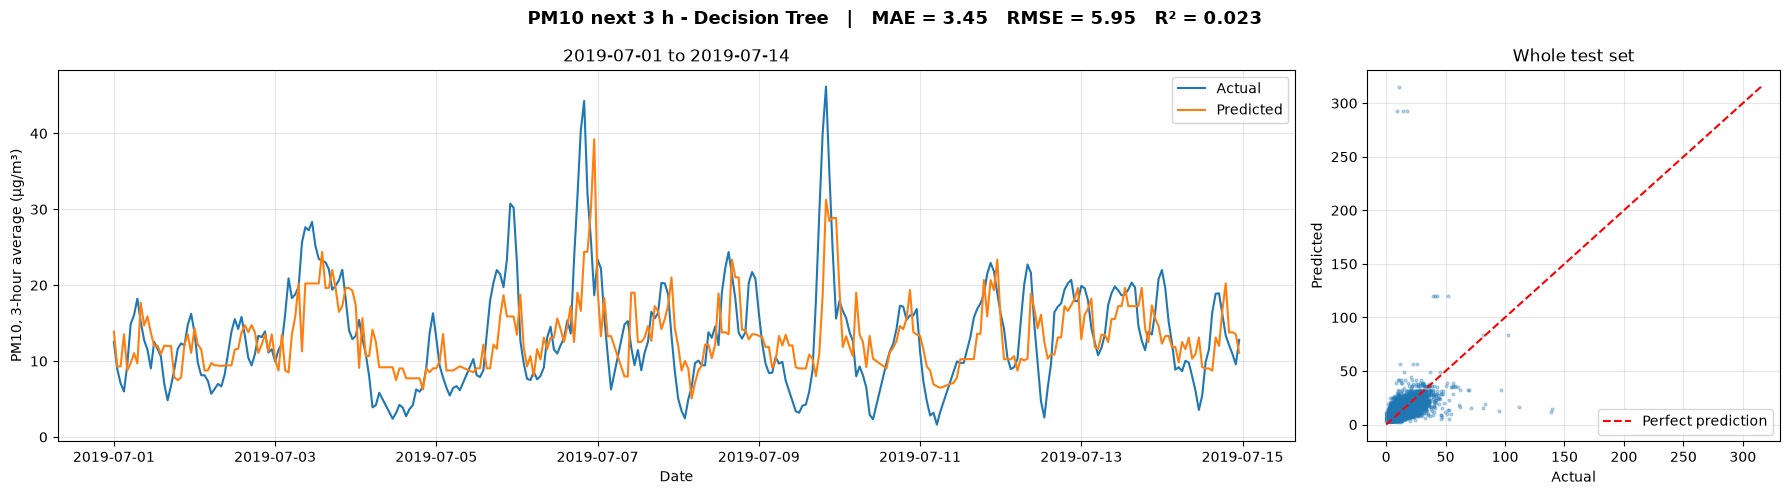

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with `

In [154]:
# Model 2: Decision Tree
run_model("Decision Tree", model_lookup["Decision Tree"](), pm10_3h_train, pm10_3h_test,
          pm10_3h_features, pm10_3h_preds, "PM10 next 3 h", pm10_3h_label)

Random Forest:  MAE = 3.302   RMSE = 5.001   R² = 0.310


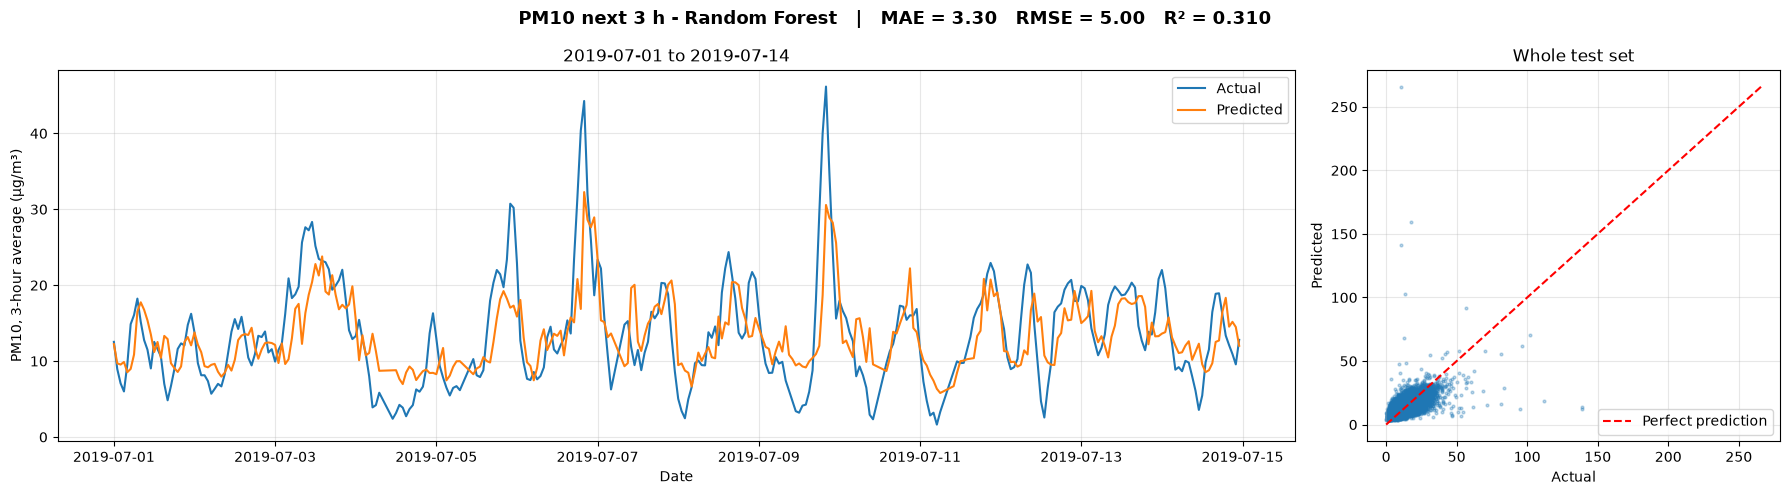

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [156]:
# Model 3: Random Forest
run_model("Random Forest", model_lookup["Random Forest"](), pm10_3h_train, pm10_3h_test,
          pm10_3h_features, pm10_3h_preds, "PM10 next 3 h", pm10_3h_label)

XGBoost (tuned):  MAE = 3.275   RMSE = 4.670   R² = 0.399


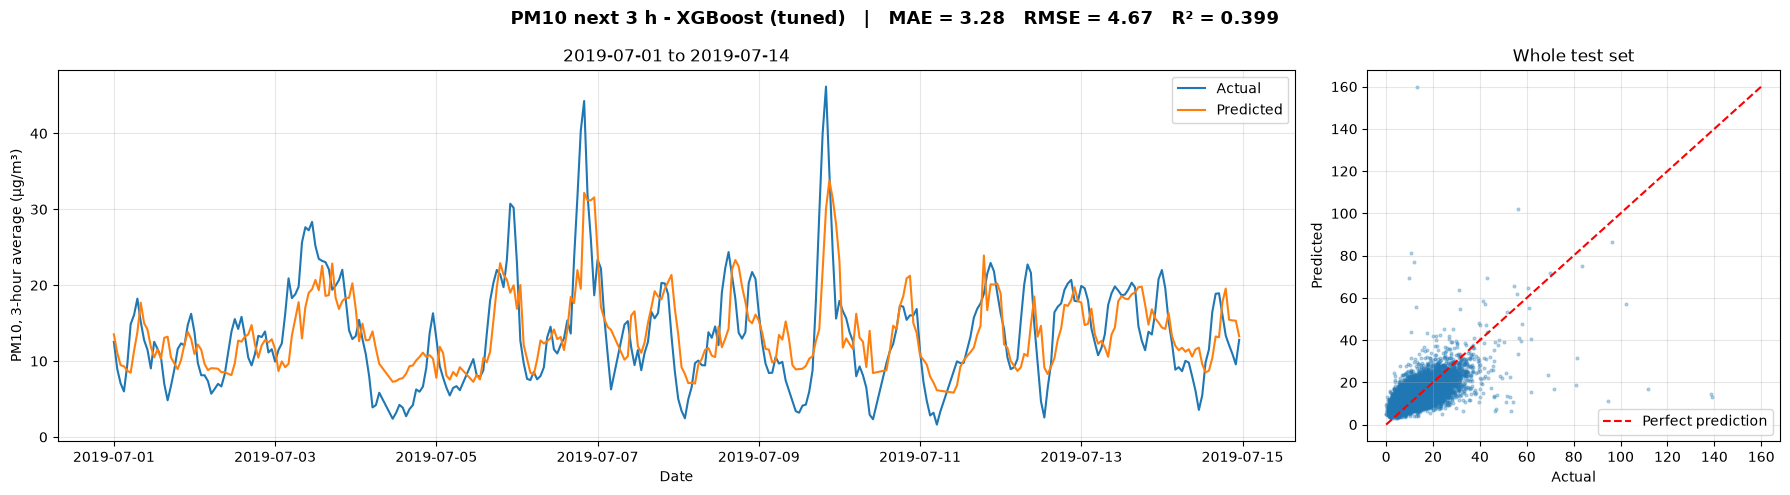

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [158]:
# Model 4: XGBoost (tuned)
run_model("XGBoost (tuned)", model_lookup["XGBoost (tuned)"](), pm10_3h_train, pm10_3h_test,
          pm10_3h_features, pm10_3h_preds, "PM10 next 3 h", pm10_3h_label)

LightGBM:  MAE = 3.227   RMSE = 4.623   R² = 0.410


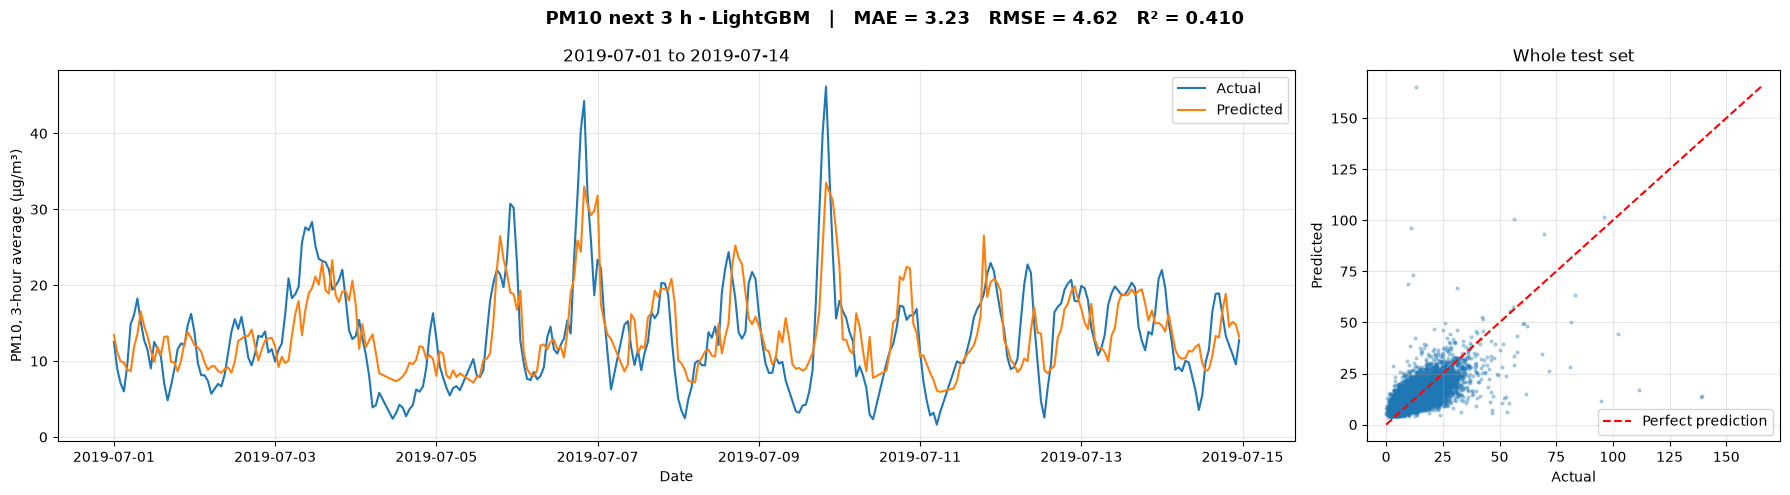

,learning_rate,0.05
,n_estimators,300
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [160]:
# Model 5: LightGBM
run_model("LightGBM", model_lookup["LightGBM"](), pm10_3h_train, pm10_3h_test,
          pm10_3h_features, pm10_3h_preds, "PM10 next 3 h", pm10_3h_label)

LightGBM (Huber):  MAE = 3.139   RMSE = 4.451   R² = 0.454


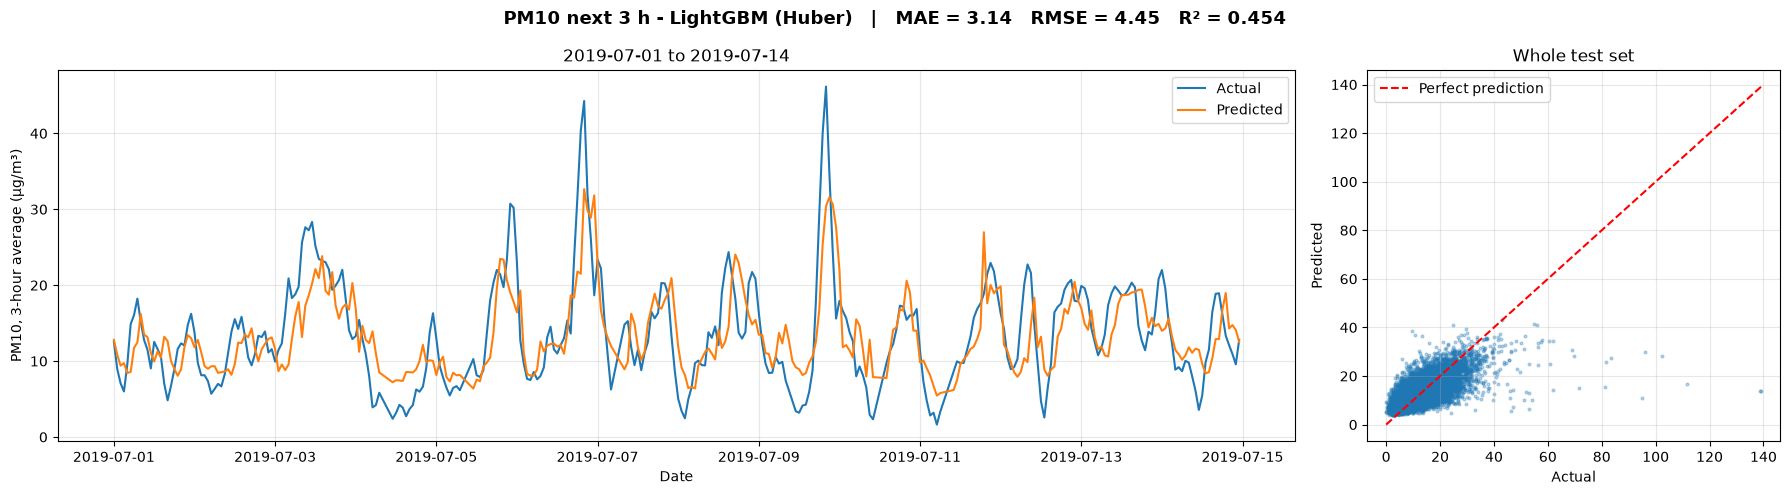

,learning_rate,0.05
,n_estimators,300
,objective,'huber'
,random_state,42
,alpha,5.0
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,class_weight,None


In [162]:
# Model 5b: LightGBM (Huber)
huber = lambda: LGBMRegressor(objective="huber", alpha=5.0, n_estimators=300,
                              learning_rate=0.05, random_state=42, verbose=-1)
run_model("LightGBM (Huber)", huber(), pm10_3h_train, pm10_3h_test,
          pm10_3h_features, pm10_3h_preds, "PM10 next 3 h", pm10_3h_label)

In [164]:
# 3-hour results
pm10_3h_results = results_table(pm10_3h_preds, pm10_3h_test, pm10_3h_naive)
display(pm10_3h_results)

pm10_3h_best = pm10_3h_results[pm10_3h_results["Model"] != "Naive (simple guess)"].iloc[0]["Model"]
print("Best 3-hour PM10 model:", pm10_3h_best)

,Model,MAE,RMSE,R2,Skill vs naive
0,LightGBM (Huber),3.139,4.451,0.454,0.208
1,LightGBM,3.227,4.623,0.410,0.177
2,XGBoost (tuned),3.275,4.670,0.399,0.169
3,Linear Regression,3.422,4.831,0.356,0.141
4,Random Forest,3.302,5.001,0.310,0.110
5,Naive (simple guess),3.851,5.620,0.129,0.000
6,Decision Tree,3.451,5.953,0.023,-0.059


Best 3-hour PM10 model: LightGBM (Huber)


In [166]:
# Handling the 2017 data change
boosting = {
    "XGBoost (tuned)": model_lookup["XGBoost (tuned)"],
    "LightGBM": model_lookup["LightGBM"],
    "LightGBM (Huber)": huber,
}
naive_rmse = np.sqrt(mean_squared_error(pm10_3h_test["target"], pm10_3h_naive))
setups = {
    "A: all years": (pm10_3h_train, pm10_3h_features),
    "B: all years + era flag": (pm10_3h_train, pm10_3h_features + ["era_2017"]),
    "C: 2017 onwards only": (pm10_3h_train[pm10_3h_train.index.year >= 2017], pm10_3h_features),
}

rows = []
for setup, (train, cols) in setups.items():
    for name, make in boosting.items():
        model = make().fit(train[cols], train["target"])
        m = evaluate(pm10_3h_test["target"], model.predict(pm10_3h_test[cols]))
        rows.append({"Setup": setup, "Model": name, **m, "Skill vs naive": 1 - m["RMSE"] / naive_rmse})
        print(f"{setup:25s} {name:17s} RMSE={m['RMSE']:.3f} R2={m['R2']:.3f}")

pm10_era_results = pd.DataFrame(rows).round(3)
display(pm10_era_results.pivot(index="Model", columns="Setup", values="R2"))

A: all years              XGBoost (tuned)   RMSE=4.670 R2=0.399
A: all years              LightGBM          RMSE=4.623 R2=0.410
A: all years              LightGBM (Huber)  RMSE=4.451 R2=0.454
B: all years + era flag   XGBoost (tuned)   RMSE=4.615 R2=0.413
B: all years + era flag   LightGBM          RMSE=4.583 R2=0.421
B: all years + era flag   LightGBM (Huber)  RMSE=4.431 R2=0.459
C: 2017 onwards only      XGBoost (tuned)   RMSE=4.694 R2=0.392
C: 2017 onwards only      LightGBM          RMSE=4.613 R2=0.413
C: 2017 onwards only      LightGBM (Huber)  RMSE=4.503 R2=0.441


Setup,A: all years,B: all years + era flag,C: 2017 onwards only
Model,,,
LightGBM,0.410,0.421,0.413
LightGBM (Huber),0.454,0.459,0.441
XGBoost (tuned),0.399,0.413,0.392


24h test: 28970 2019-08-07 22:00:00 to 2023-02-27 23:00:00


,Model,MAE,RMSE,R2,Skill vs naive
0,LightGBM (Huber),2.690,3.468,0.212,0.098
1,XGBoost (tuned),2.766,3.536,0.182,0.081
2,LightGBM,2.771,3.561,0.170,0.074
3,Naive (simple guess),2.749,3.846,0.031,0.000


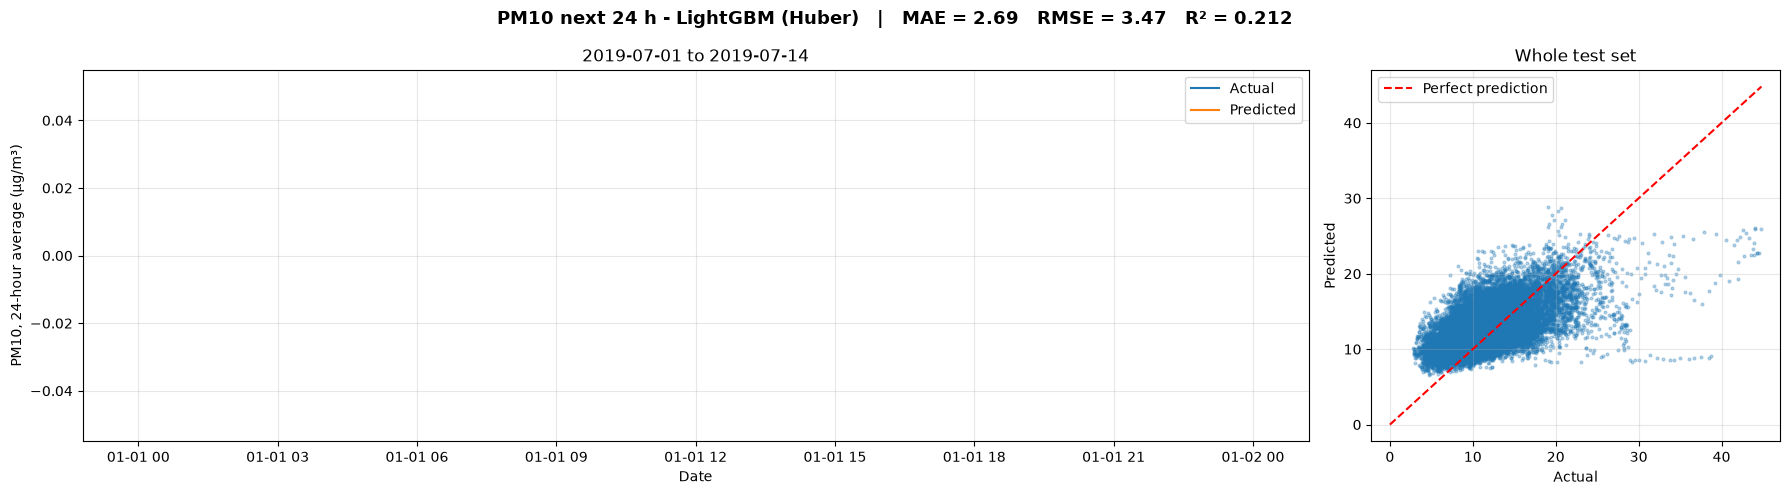

In [168]:
# Comparison: next 24-hour average
pm10_24h = make_pm10_avg(df, 24)
pm10_24h_train, pm10_24h_test = split_avg(pm10_24h, 24)
print("24h test:", len(pm10_24h_test), pm10_24h_test.index.min(), "to", pm10_24h_test.index.max())

# simple guess: next 24-hour average = last 24-hour average
pm10_24h_naive = pm10_24h_test["PM10_roll24"].fillna(pm10_24h_test["PM10_lag0"])
pm10_24h_preds, pm10_24h_models = {}, {}
for name, make in boosting.items():
    model = make().fit(pm10_24h_train[pm10_3h_features], pm10_24h_train["target"])
    pm10_24h_models[name] = model
    pm10_24h_preds[name] = pd.Series(model.predict(pm10_24h_test[pm10_3h_features]), index=pm10_24h_test.index)

pm10_24h_results = results_table(pm10_24h_preds, pm10_24h_test, pm10_24h_naive)
display(pm10_24h_results)

pm10_24h_best = pm10_24h_results[pm10_24h_results["Model"] != "Naive (simple guess)"].iloc[0]["Model"]
plot_actual_vs_pred(pm10_24h_test["target"], pm10_24h_preds[pm10_24h_best],
                    f"PM10 next 24 h - {pm10_24h_best}", "PM10, 24-hour average (µg/m³)")

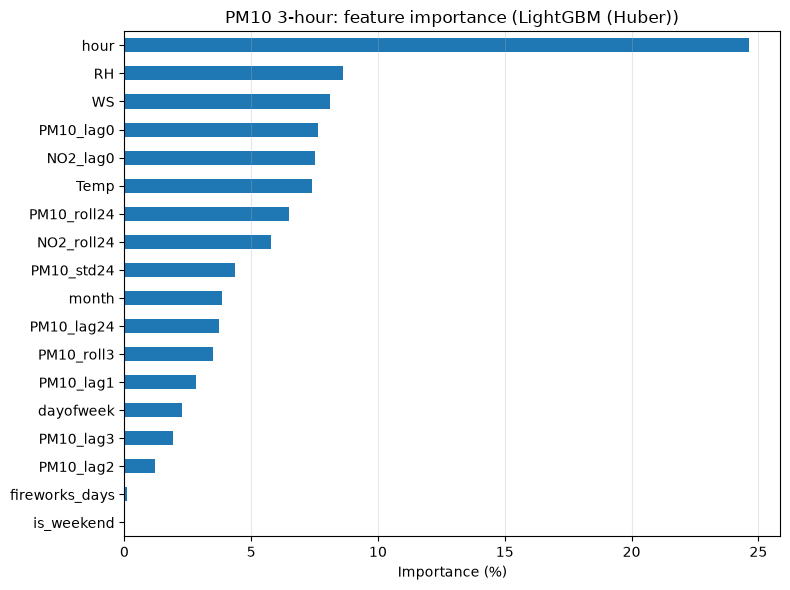

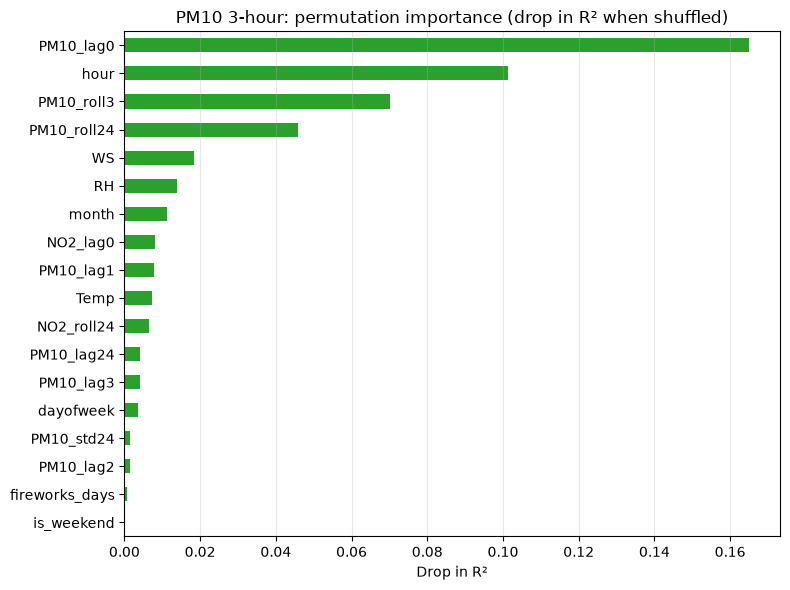

In [170]:
# rebuild and train the best 3-hour model
pm10_3h_makers = {**model_lookup, "LightGBM (Huber)": huber,
                  "Linear Regression": lambda: make_pipeline(SimpleImputer(strategy="mean"), LinearRegression())}
pm10_3h_model = pm10_3h_makers[pm10_3h_best]()
pm10_3h_model.fit(pm10_3h_train[pm10_3h_features], pm10_3h_train["target"])

if hasattr(pm10_3h_model, "feature_importances_"):
    imp = pd.Series(pm10_3h_model.feature_importances_, index=pm10_3h_features)
    imp = (imp / imp.sum() * 100).sort_values()
    imp.plot(kind="barh", figsize=(8, 6), color="tab:blue")
    plt.title(f"PM10 3-hour: feature importance ({pm10_3h_best})")
    plt.xlabel("Importance (%)")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

perm = permutation_importance(pm10_3h_model, pm10_3h_test[pm10_3h_features], pm10_3h_test["target"],
                              n_repeats=5, random_state=42, n_jobs=-1, scoring="r2")
pd.Series(perm.importances_mean, index=pm10_3h_features).sort_values().plot(kind="barh", figsize=(8, 6), color="tab:green")
plt.title("PM10 3-hour: permutation importance (drop in R² when shuffled)")
plt.xlabel("Drop in R²")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

,Removed,R2 without,Drop in R2
0,Weather,0.442,0.011
1,Recent PM10,0.029,0.424
2,NO2 (traffic),0.447,0.006
3,Time,0.416,0.038


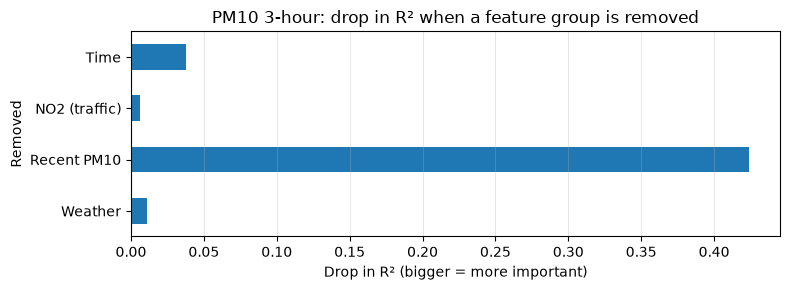

In [171]:
# group importance: remove a group of features, retrain, compare R2
pm10_groups = {
    "Weather": ["Temp", "RH", "WS"],
    "Recent PM10": ["PM10_lag0", "PM10_lag1", "PM10_lag2", "PM10_lag3", "PM10_lag24",
                    "PM10_roll3", "PM10_roll24", "PM10_std24"],
    "NO2 (traffic)": ["NO2_lag0", "NO2_roll24"],
    "Time": ["hour", "month", "dayofweek", "is_weekend", "fireworks_days"],
}
base_r2 = r2_score(pm10_3h_test["target"], pm10_3h_model.predict(pm10_3h_test[pm10_3h_features]))
rows = []
for group, cols in pm10_groups.items():
    keep = [c for c in pm10_3h_features if c not in cols]
    m = pm10_3h_makers[pm10_3h_best]().fit(pm10_3h_train[keep], pm10_3h_train["target"])
    r2 = r2_score(pm10_3h_test["target"], m.predict(pm10_3h_test[keep]))
    rows.append({"Removed": group, "R2 without": round(r2, 3), "Drop in R2": round(base_r2 - r2, 3)})
pm10_groups_df = pd.DataFrame(rows)
display(pm10_groups_df)

pm10_groups_df.set_index("Removed")["Drop in R2"].plot(kind="barh", figsize=(8, 3), color="tab:blue")
plt.title("PM10 3-hour: drop in R² when a feature group is removed")
plt.xlabel("Drop in R² (bigger = more important)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [174]:
# Final summary and files 
summary = pd.concat([
    no2_results.assign(Pollutant="NO2", Forecast="next hour"),
    pm10_hourly_results.assign(Pollutant="PM10", Forecast="next hour"),
    pm10_3h_results.assign(Pollutant="PM10", Forecast="next 3 h average (main)"),
    pm10_24h_results.assign(Pollutant="PM10", Forecast="next 24 h average"),
])
best_rows = summary[summary["Model"] != "Naive (simple guess)"].groupby(["Pollutant", "Forecast"], sort=False).head(1)
naive_rows = summary[summary["Model"] == "Naive (simple guess)"]
print("Best model for each forecast")
display(best_rows[["Pollutant", "Forecast", "Model", "MAE", "RMSE", "R2", "Skill vs naive"]])
print("Naive (simple guess) for comparison")
display(naive_rows[["Pollutant", "Forecast", "MAE", "RMSE", "R2"]])

Best model for each forecast


,Pollutant,Forecast,Model,MAE,RMSE,R2,Skill vs naive
0,NO2,next hour,LightGBM,2.501,3.909,0.783,0.207
0,PM10,next hour,LightGBM,4.175,5.786,0.376,0.189
0,PM10,next 3 h average (main),LightGBM (Huber),3.139,4.451,0.454,0.208
0,PM10,next 24 h average,LightGBM (Huber),2.690,3.468,0.212,0.098


Naive (simple guess) for comparison


,Pollutant,Forecast,MAE,RMSE,R2
5,NO2,next hour,2.874,4.928,0.655
5,PM10,next hour,5.254,7.134,0.051
5,PM10,next 3 h average (main),3.851,5.620,0.129
3,PM10,next 24 h average,2.749,3.846,0.031


In [176]:
# Save models and predictions 
os.makedirs("models", exist_ok=True)

# next-hour models (Prophet is not saved: the dashboard needs a model that uses the recent hours)
pm10_hourly_model = model_lookup[pm10_hourly_best]().fit(pm10_train[pm10_features], pm10_train["target"])
joblib.dump(no2_model, "models/best_model_NO2.pkl", compress=3)
joblib.dump(pm10_hourly_model, "models/best_model_PM10.pkl", compress=3)

# averaged PM10 models, saved with their feature list
joblib.dump({"model": pm10_3h_model, "features": pm10_3h_features, "hours": 3,
             "setup": "A: all years", "name": pm10_3h_best}, "models/pm10_3h_model.pkl", compress=3)
joblib.dump({"model": pm10_24h_models[pm10_24h_best], "features": pm10_3h_features, "hours": 24,
             "setup": "A: all years", "name": pm10_24h_best}, "models/pm10_24h_model.pkl", compress=3)

# next-hour predictions: datetime = the hour being predicted
pred_df = pd.concat([
    pd.DataFrame({"datetime": no2_test.index + pd.Timedelta(hours=1), "pollutant": "NO2", "model": no2_best,
                  "actual": no2_test["target"].values, "predicted": no2_preds[no2_best].values}),
    pd.DataFrame({"datetime": pm10_test.index + pd.Timedelta(hours=1), "pollutant": "PM10", "model": pm10_hourly_best,
                  "actual": pm10_test["target"].values, "predicted": pm10_preds[pm10_hourly_best].values}),
])
pred_df.to_csv("predictions_test.csv", index=False)

# averaged PM10 predictions: datetime = when the forecast is made
avg_df = pd.concat([
    pd.DataFrame({"datetime": pm10_3h_test.index, "horizon_hours": 3, "model": pm10_3h_best,
                  "actual": pm10_3h_test["target"].values,
                  "predicted": np.clip(pm10_3h_preds[pm10_3h_best].values, 0, None)}),
    pd.DataFrame({"datetime": pm10_24h_test.index, "horizon_hours": 24, "model": pm10_24h_best,
                  "actual": pm10_24h_test["target"].values,
                  "predicted": np.clip(pm10_24h_preds[pm10_24h_best].values, 0, None)}),
])
avg_df.to_csv("predictions_pm10_avg.csv", index=False)

for f in sorted(os.listdir("models")):
    print(f, round(os.path.getsize(f"models/{f}") / 1e6, 1), "MB")
print("predictions_test.csv", pred_df.shape, "| predictions_pm10_avg.csv", avg_df.shape)

best_model_NO2.pkl 0.3 MB
best_model_PM10.pkl 0.3 MB
pm10_24h_model.pkl 0.3 MB
pm10_3h_model.pkl 0.3 MB
predictions_test.csv (50347, 5) | predictions_pm10_avg.csv (56964, 5)
